<div style="display: flex; background-color: RGB(255,114,0);" >
<h1 style="margin: auto; padding: 30px; ">ANALYSE DU STOCK ET DES VENTES DU SITE BOTTLENECK</h1>
</div>

# OBJECTIF DE CE NOTEBOOK

Ce notebook reprend, fiabilise et prolonge l'analyse des ventes et du stock de l'entreprise (boutique + site internet **Bottleneck**). Il s'appuie sur trois extractions :

| Source | Contenu | Date / période |
|---|---|---|
| **ERP** | données commerciales et stocks des produits | situation au **31 octobre** |
| **Web** | données éditoriales et **ventes mensuelles** du site (`total_sales`) | ventes du **1er au 31 octobre** |
| **Liaison** | table de correspondance des codes produits ERP ↔ web | — |

**Contexte de lecture : nous sommes début novembre.** Le stock de **champagne** est destiné aux fortes ventes de **décembre** : un surstock sur cette famille est donc **normal** et n'est pas traité comme une anomalie (voir 5.6).

**Plan (inchangé par rapport au travail d'origine)** : 1 - Librairies, paramètres et chargement · 2 - Analyse exploratoire, récapitulatif des anomalies et nettoyage · 3 - Jonction · 4 - Analyse univariée des prix · 5 - CA, quantités, stock, marge, multivarié, **alertes et décisions de stock** · 6 - Recommandations.

**Principes de ce notebook**
- 🛡️ **traçabilité** (empreinte des sources, journal du traitement, journal des anomalies, colonnes de contrôle dans l'export) et **contrôle qualité** (règles testées avant et après nettoyage) ;
- **aucune donnée supprimée** pour cause d'anomalie : les valeurs erronées sont corrigées, l'ancienne valeur est conservée et la ligne est marquée ;
- **aucun chemin de fichier n'est affiché** ni exporté ; les données sensibles (prix d'achat, marges) peuvent être exclues de l'export (paramètre `EXPORT_COLONNES_SENSIBLES`) ;
- les résultats chiffrés sont **calculés par le code**, graphiques réalisés avec **Plotly**.

### Ce qui est repris, corrigé et ajouté par rapport au travail d'origine

| Thème | Évolution | Étape |
|---|---|---|
| Structure | l'analyse exploratoire **détecte** sans rien modifier ; un **récapitulatif des anomalies** la conclut ; **tout le nettoyage** est regroupé ensuite | 2.1 à 2.6 |
| Nettoyage | prix, stock et ventes négatifs **corrigés sans supprimer de ligne** ; stock_status recalculé ; colonnes web inutiles supprimées | 2.5 |
| Jonction | `merge(validate, indicator)`, **récapitulatif chiffré par statut**, clé de repli via le `guid`, colonnes de contrôle exportées | 3 |
| Prix | z-score et écart interquartile (IQR) calculés correctement et comparés ; histogramme, box plots par famille | 4 |
| Ventes / stock | top 20 CA et ventes, **courbes de Pareto 20/80 des ventes**, **classes ABC des ventes**, flop 20 stock | 5.1 à 5.3 |
| Stock | **situation de stock** global / par famille / par produit | 5.3 |
| Corrélations | matrice simple, **nuages quantités vendues vs prix et vs stock** | 5.5 |
| Pilotage | **système d'alerte à 8 statuts** surstock / sous-stock et **aide à la décision** (promotion ou réapprovisionnement) | 5.6 |
| Export | extraction Excel multi-onglets : données + contrôles + alertes + décisions + synthèses | 5.7 |

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies, paramètres et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
import hashlib
import io
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import plotly
import plotly.express as px

warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl")
pd.set_option("display.max_columns", None)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.2 - Paramètres de l'analyse</h3>
</div>

> **🛡️ Data governance :** tous les paramètres (sources, hypothèses métier, seuils) sont regroupés ici. Les noms de fichiers ne sont lus que par la fonction de chargement et **ne sont jamais affichés** ; ils peuvent être surchargés sans toucher au reste du code.

In [2]:
# --- Sources (noms logiques -> fichiers). Jamais affichés dans le notebook.
DOSSIER_DONNEES = Path(".")
NOMS_FICHIERS = {"erp": "erp.xlsx", "web": "web.xlsx", "liaison": "liaison.xlsx"}
DOSSIER_SORTIE = Path("sortie")
DOSSIER_SORTIE.mkdir(exist_ok=True)

# --- Contexte des données
PERIODE_SOURCES = {"erp": "situation au 31 octobre", "web": "ventes du 1er au 31 octobre", "liaison": "table de correspondance"}
PERIODE_VENTES_MOIS = 1            # total_sales = ventes d'UN mois (confirmé : 1er au 31 octobre)

# --- Données sensibles : prix d'achat, marges et valorisations au coût
EXPORT_COLONNES_SENSIBLES = True   # False => ces colonnes sont retirées de TOUS les onglets de l'export
COLONNES_SENSIBLES = ["purchase_price", "marge_unitaire", "taux_marque", "taux_marge", "marge_totale",
                      "valo_stock_cout", "valeur_stock_a_ecouler_cout", "cout_reappro_estime"]

# --- Hypothèses métier fiscales
TVA_DEFAUT = 0.20
TVA_PAR_TYPE = {"Huile d'olive": 0.055}      # taux réduit alimentaire : hypothèse à confirmer

# --- Seuils statistiques (outliers, Pareto, ABC)
SEUIL_Z = 3
SEUIL_Z_ROBUSTE = 3.5
COEF_IQR = 1.5
SEUIL_PARETO = 0.80
SEUILS_ABC = (0.50, 0.80)          # A = 50 premiers % du total, B = jusqu'à 80 %, C = le reste (distribution plate : 80/95 serait peu discriminant)

# --- Gestion du stock (calibrés sur la distribution observée : couverture médiane ~2,4 mois, 95 % des produits sous 4 mois)
COUVERTURE_CIBLE_MOIS = 3.0        # niveau de stock visé après réapprovisionnement
SEUIL_SOUS_STOCK_MOIS = 1.5        # en dessous : sous-stock
SEUIL_SURSTOCK_MOIS = 4.0          # au-dessus : surstock
FAMILLE_SAISONNIERE = "Champagne"  # famille dont le stock prépare les ventes de décembre
COEF_SAISON_DECEMBRE = 2.0         # HYPOTHESE : ventes de décembre = 2 x ventes d'octobre. A calibrer avec l'historique de décembre N-1.
PART_MARGE_CEDEE = 0.5             # une promotion peut céder au maximum la moitié de la marge unitaire...
REMISE_MAX = 0.30                  # ... et jamais plus de 30 %

# --- Reclassement du type de produit d'après le titre web
REGLES_TYPE = [(r"Eau de Vie", "Eau de vie"), (r"Coteaux Champenois", "Vin")]

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.3 - Fonctions utilitaires</h3>
</div>

In [3]:
anomalies = []          # journal des anomalies et des corrections
journal_pipeline = []   # journal de traçabilité du traitement (volumétrie à chaque étape)


def tracer(etape, objet, df, commentaire=""):
    """Enregistre la volumétrie d'un jeu de données à une étape du traitement."""
    journal_pipeline.append({"horodatage": datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "etape": etape,
                             "objet": objet, "nb_lignes": len(df), "nb_colonnes": df.shape[1], "commentaire": commentaire})


def journaliser(source, df, cle, champ, constat, action):
    """Ajoute au journal une ligne par enregistrement concerné (à appeler AVANT de modifier la donnée)."""
    for _, ligne in df.iterrows():
        anomalies.append({"source": source, "cle": ligne[cle], "champ": champ,
                          "valeur_initiale": ligne[champ] if champ in df.columns else None,
                          "constat": constat, "action": action})


def charger(nom_logique):
    """Charge une source en mémoire et renvoie (DataFrame, empreinte SHA-256). Ne révèle jamais le chemin."""
    chemin = DOSSIER_DONNEES / NOMS_FICHIERS[nom_logique]
    try:
        octets = chemin.read_bytes()
    except FileNotFoundError:
        raise FileNotFoundError(f"Source « {nom_logique} » introuvable : vérifier le paramétrage (cellule 1.2).") from None
    return pd.read_excel(io.BytesIO(octets)), hashlib.sha256(octets).hexdigest()[:12]


def profil(df):
    return pd.DataFrame({"type": df.dtypes.astype(str), "renseignees": df.notna().sum(),
                         "manquantes_%": (df.isna().mean() * 100).round(1), "valeurs_distinctes": df.nunique()})


def normaliser_cle(serie):
    return serie.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)


def mise_en_forme(fig, titre, hauteur=None):
    fig.update_layout(title={"text": titre, "x": 0.5, "xanchor": "center"}, font=dict(family="Arial", size=14, color="black"))
    if hauteur:
        fig.update_layout(height=hauteur)
    return fig


def titre_court(texte, n=45):
    texte = str(texte)
    return texte if len(texte) <= n else texte[: n - 1] + "…"


def force_correlation(r):
    for seuil, libelle in [(0.2, "très faible"), (0.4, "faible"), (0.6, "modérée"), (0.8, "forte")]:
        if abs(r) < seuil:
            return libelle
    return "très forte"


def pareto(df, colonne, seuil=SEUIL_PARETO):
    """Loi des 20/80 exacte sur les produits dont la valeur est > 0 (sans arrondi avant cumul)."""
    d = df[df[colonne] > 0].sort_values(colonne, ascending=False).copy()
    d["part"] = d[colonne] / d[colonne].sum()
    d["cumul"] = d["part"].cumsum()
    d["rang_pct"] = np.arange(1, len(d) + 1) / len(d)
    return d, int((d["cumul"] < seuil).sum() + 1)


def classes_abc(d, seuils=SEUILS_ABC):
    """Classe A/B/C d'après la part cumulée AVANT le produit (le produit qui franchit le seuil reste dans la classe)."""
    avant = d["cumul"] - d["part"]
    return pd.Series(np.select([avant < seuils[0], avant < seuils[1]], ["A", "B"], "C"), index=d.index)


def controler(erp, web, liaison, phase):
    """Contrôle qualité : applique les règles de qualité aux 3 sources et renvoie un tableau (une ligne par règle)."""
    lignes = []

    def regle(source, nom, severite, masque, cles, traitement):
        masque = masque.fillna(False).astype(bool)
        lignes.append({"phase": phase, "source": source, "regle": nom, "severite": severite,
                       "nb_controles": int(len(masque)), "nb_violations": int(masque.sum()),
                       "exemples_cles": ", ".join(map(str, cles[masque].head(5).tolist())), "traitement": traitement})

    # --- ERP
    attendu = pd.Series(np.where(erp["stock_quantity"] <= 0, "outofstock", "instock"), index=erp.index)
    pid = erp["product_id"]
    regle("erp", "product_id unique", "Bloquante", erp["product_id"].duplicated(keep=False), pid, "aucun traitement nécessaire")
    regle("erp", "prix de vente renseigné et > 0", "Critique", ~(erp["price"] > 0), pid, "valeur absolue si cohérent, sinon estimation (2.5.1)")
    regle("erp", "quantité en stock >= 0", "Critique", erp["stock_quantity"] < 0, pid, "ramenée à 0 (2.5.1)")
    regle("erp", "stock_status cohérent avec stock_quantity", "Elevée", erp["stock_status"] != attendu, pid, "statut recalculé (2.5.1)")
    regle("erp", "prix d'achat renseigné et > 0", "Critique", ~(erp["purchase_price"] > 0), pid, "aucun traitement nécessaire")
    regle("erp", "prix de vente TTC >= prix d'achat HT", "Elevée", erp["price"] < erp["purchase_price"], pid, "signalé, exclu des moyennes de marge (5.4)")
    regle("erp", "onsale_web valant 0 ou 1", "Moyenne", ~erp["onsale_web"].isin([0, 1]), pid, "aucun traitement nécessaire")

    # --- WEB
    cols_id = [c for c in ["sku", "post_title", "post_type"] if c in web.columns]
    est_prod = web["post_type"].eq("product") if "post_type" in web.columns else pd.Series(True, index=web.index)
    idx = pd.Series(web.index, index=web.index)
    sku_prod = web["sku"].where(est_prod)
    non_conforme = ~web["sku"].str.fullmatch(r"\d+").fillna(True)
    regle("web", "ligne entièrement vide", "Moyenne", web[cols_id].isna().all(axis=1), idx, "exclue du jeu de travail (2.5.2)")
    regle("web", "fiche produit sans sku", "Elevée", est_prod & web["sku"].isna(), web["id_wp"], "rattachée à l'ERP via l'identifiant du guid (3.2)")
    regle("web", "sku dupliqué parmi les fiches produit", "Bloquante", sku_prod.notna() & sku_prod.duplicated(keep=False), web["sku"], "aucun traitement nécessaire")
    regle("web", "sku non conforme à la codification numérique", "Information", est_prod & non_conforme & web["sku"].notna(), web["sku"], "conservé tel quel, en texte")
    regle("web", "ventes mensuelles >= 0", "Critique", est_prod & (web["total_sales"] < 0), web["id_wp"], "ramenées à 0 (ventes nettes), ligne conservée (2.5.2)")
    regle("web", "type de produit renseigné (fiches produit)", "Moyenne", est_prod & web["product_type"].isna(), web["id_wp"], "complété depuis le visuel associé (2.5.2)")

    # --- LIAISON
    skus_web = web.loc[est_prod, "sku"]
    regle("liaison", "product_id unique", "Bloquante", liaison["product_id"].duplicated(keep=False), liaison["product_id"], "aucun traitement nécessaire")
    regle("liaison", "id_web unique", "Bloquante", liaison["id_web"].notna() & liaison["id_web"].duplicated(keep=False), liaison["product_id"], "aucun traitement nécessaire")
    regle("liaison", "id_web renseigné", "Elevée", liaison["id_web"].isna(), liaison["product_id"], "clé de repli via le guid du site (3.2)")
    regle("liaison", "id_web présent dans le fichier web", "Moyenne", liaison["id_web"].notna() & ~liaison["id_web"].isin(skus_web), liaison["product_id"], "produit non publié : aucune donnée web (3.2)")
    return pd.DataFrame(lignes)

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">1.4 - Chargement des fichiers et traçabilité des sources</h3>
</div>

> **🛡️ Data governance :** chaque source est identifiée par une **empreinte SHA-256** (12 premiers caractères) : si un fichier change, l'empreinte change et la différence de résultat est explicable. Seuls des **noms logiques** sont affichés.

In [4]:
df_erp, empreinte_erp = charger("erp")
df_web, empreinte_web = charger("web")
df_liaison, empreinte_liaison = charger("liaison")

# Les clés de jonction sont des identifiants : on les traite en TEXTE
df_web["sku"] = normaliser_cle(df_web["sku"])
df_liaison["id_web"] = normaliser_cle(df_liaison["id_web"])

tracabilite_sources = pd.DataFrame([
    {"source": nom, "periode": PERIODE_SOURCES[nom], "empreinte_sha256": emp, "nb_lignes": d.shape[0], "nb_colonnes": d.shape[1],
     "charge_le": datetime.now().strftime("%Y-%m-%d %H:%M:%S")}
    for nom, d, emp in [("erp", df_erp, empreinte_erp), ("web", df_web, empreinte_web), ("liaison", df_liaison, empreinte_liaison)]])
display(tracabilite_sources)
print(f"Exécution : pandas {pd.__version__} | numpy {np.__version__} | plotly {plotly.__version__}")

N_ERP_INITIAL = len(df_erp)
for nom, d in [("erp", df_erp), ("web", df_web), ("liaison", df_liaison)]:
    tracer("1.4 chargement", nom, d, "données brutes")

,source,periode,empreinte_sha256,nb_lignes,nb_colonnes,charge_le
0,erp,situation au 31 octobre,1179ffa64794,825,6,2026-10-21 17:55:24
1,web,ventes du 1er au 31 octobre,24f3ecdb4ea9,1513,29,2026-10-21 17:55:24
2,liaison,table de correspondance,b3af2411c597,825,2,2026-10-21 17:55:24


Exécution : pandas 2.3.3 | numpy 2.3.5 | plotly 6.3.0


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire, récapitulatif des anomalies et nettoyage des fichiers</h2>
</div>

Cette étape est organisée en deux temps : **(A) l'analyse exploratoire (2.1 à 2.3) ne modifie aucune donnée**, elle ne fait que détecter ; **(B) le récapitulatif des anomalies (2.4) clôt l'exploration**, puis **(C) tout le nettoyage est regroupé (2.5)** et suivi d'un contrôle qualité « après » (2.6).

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1 - Analyse exploratoire du fichier ERP</h3>
</div>

In [5]:
print(f"Le tableau comporte {df_erp.shape[0]} article(s) et {df_erp.shape[1]} colonne(s)")
display(profil(df_erp))
display(df_erp.head(5))
display(df_erp.describe().round(2))
print("Doublons sur product_id :", df_erp["product_id"].duplicated().sum())

Le tableau comporte 825 article(s) et 6 colonne(s)


,type,renseignees,manquantes_%,valeurs_distinctes
product_id,int64,825,0.0,825
onsale_web,int64,825,0.0,2
price,float64,825,0.0,383
stock_quantity,int64,825,0.0,84
stock_status,object,825,0.0,2
purchase_price,float64,825,0.0,660


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
0,3847,1,24.2,16,instock,12.88
1,3849,1,34.3,10,instock,17.54
2,3850,1,20.8,0,outofstock,10.64
3,4032,1,14.1,26,instock,6.92
4,4039,1,46.0,3,outofstock,23.77


,product_id,onsale_web,price,stock_quantity,purchase_price
count,825.00,825.00,825.00,825.00,825.00
mean,5162.60,0.87,32.19,21.59,16.94
std,902.64,0.34,26.71,21.93,14.56
min,3847.00,0.00,-20.00,-10.00,2.74
25%,4348.00,1.00,14.50,7.00,7.59
50%,4907.00,1.00,24.30,18.00,12.71
75%,5805.00,1.00,42.00,30.00,22.02
max,7338.00,1.00,225.00,145.00,137.81


Doublons sur product_id : 0


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.0 - Cohérence entre stock_status et stock_quantity</h3>
</div>

In [6]:
statut_attendu = np.where(df_erp["stock_quantity"] <= 0, "outofstock", "instock")
ecarts_statut = df_erp[df_erp["stock_status"] != statut_attendu]
print(df_erp["stock_status"].value_counts().to_string(), "\n")
print(f"Lignes dont le statut est incohérent avec la quantité : {len(ecarts_statut)}")
display(ecarts_statut)

stock_status
instock       733
outofstock     92 

Lignes dont le statut est incohérent avec la quantité : 2


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
4,4039,1,46.0,3,outofstock,23.77
398,4885,1,18.7,0,instock,9.66


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1 - Analyse exploratoire de chaque variable du fichier ERP</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.1 - Analyse de la variable PRIX</h3>
</div>

In [7]:
print("Prix non renseignés :", df_erp["price"].isna().sum())
print("Prix minimum        :", df_erp["price"].min())
print("Prix maximum        :", df_erp["price"].max())
prix_invalides = df_erp[~(df_erp["price"] > 0)]
print(f"\nPrix négatifs, nuls ou vides : {len(prix_invalides)}")
display(prix_invalides)

Prix non renseignés : 0
Prix minimum        : -20.0
Prix maximum        : 225.0

Prix négatifs, nuls ou vides : 3


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
151,4233,0,-20.0,0,outofstock,10.33
469,5017,0,-8.0,0,outofstock,4.34
739,6594,0,-9.1,19,instock,4.61


In [8]:
# Rapport prix de vente / prix d'achat : très homogène dans un catalogue, il sert de repère de vraisemblance
valide = df_erp["price"] > 0
ratio_catalogue = df_erp.loc[valide, "price"] / df_erp.loc[valide, "purchase_price"]
print(ratio_catalogue.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_string())

# Prix de vente TTC inférieur au prix d'achat HT : forcément une erreur de saisie (ou une vente à perte)
prix_sous_cout = df_erp[df_erp["price"] < df_erp["purchase_price"]]
print(f"\nPrix de vente inférieur au prix d'achat : {len(prix_sous_cout)}")
display(prix_sous_cout.assign(ratio=(prix_sous_cout["price"] / prix_sous_cout["purchase_price"]).round(2)))

0.05    1.84
0.25    1.88
0.50    1.94
0.75    2.00
0.95    2.04

Prix de vente inférieur au prix d'achat : 7


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price,ratio
151,4233,0,-20.00,0,outofstock,10.33,-1.94
210,4355,1,12.65,97,instock,77.48,0.16
391,4864,0,8.30,0,outofstock,9.99,0.83
469,5017,0,-8.00,0,outofstock,4.34,-1.84
724,6324,0,92.00,18,instock,99.00,0.93
739,6594,0,-9.10,19,instock,4.61,-1.97
817,7196,0,31.00,55,instock,31.20,0.99


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.2 - Analyse de la variable STOCK</h3>
</div>

In [9]:
print("Stock minimum :", df_erp["stock_quantity"].min())
print("Stock maximum :", df_erp["stock_quantity"].max())
stock_negatif = df_erp[df_erp["stock_quantity"] < 0]
print(f"\nStocks négatifs : {len(stock_negatif)}")
display(stock_negatif)

Stock minimum : -10
Stock maximum : 145

Stocks négatifs : 2


,product_id,onsale_web,price,stock_quantity,stock_status,purchase_price
449,4973,0,10.0,-10,outofstock,4.96
573,5700,1,44.5,-1,outofstock,22.30


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.3 - Analyse de la variable ONSALE_WEB</h3>
</div>

In [10]:
print(df_erp["onsale_web"].value_counts().sort_index().to_string())
# Hypothèse : 1 = produit publié sur le site, 0 = non publié. Elle est vérifiée à l'étape 3.

onsale_web
0    109
1    716


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.1.1.4 - Analyse de la variable prix d'achat</h3>
</div>

In [11]:
print("Prix d'achat non renseignés :", df_erp["purchase_price"].isna().sum())
print("Prix d'achat <= 0           :", (df_erp["purchase_price"] <= 0).sum())
print("Prix d'achat minimum / maximum :", df_erp["purchase_price"].min(), "/", df_erp["purchase_price"].max())

Prix d'achat non renseignés : 0
Prix d'achat <= 0           : 0
Prix d'achat minimum / maximum : 2.74 / 137.81


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2 - Analyse exploratoire du fichier web</h3>
</div>

In [12]:
print(f"Le tableau comporte {df_web.shape[0]} lignes et {df_web.shape[1]} colonnes")
display(profil(df_web))

Le tableau comporte 1513 lignes et 29 colonnes


,type,renseignees,manquantes_%,valeurs_distinctes
sku,string,1428,5.6,714
virtual,int64,1513,0.0,1
downloadable,int64,1513,0.0,1
rating_count,int64,1513,0.0,1
average_rating,float64,1430,5.5,1
total_sales,float64,1430,5.5,29
tax_status,object,716,52.7,1
tax_class,float64,0,100.0,0
post_author,float64,1430,5.5,2
post_date,datetime64[ns],1430,5.5,716


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.1 - Structure des lignes du fichier web</h3>
</div>

In [13]:
print(df_web["post_type"].value_counts(dropna=False).to_string())
lignes_vides = df_web[["sku", "post_title", "post_type"]].isna().all(axis=1)
print("\nLignes entièrement vides :", lignes_vides.sum())

# Identifiant WordPress contenu dans le guid des fiches produit : colonne technique ajoutée (aucune donnée modifiée)
df_web["id_wp"] = pd.to_numeric(df_web["guid"].str.extract(r"p=(\d+)$")[0]).astype("Int64")
print("Fiches produit dont le guid contient un identifiant :", df_web.loc[df_web["post_type"] == "product", "id_wp"].notna().sum())

post_type
product       716
attachment    714
NaN            83

Lignes entièrement vides : 83
Fiches produit dont le guid contient un identifiant : 716


Le fichier mélange **3 types de lignes** : les fiches produit (`product`), les visuels associés (`attachment`, un par produit, qui dupliquent le `sku`) et des lignes entièrement vides.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.2 - Analyse de la clé sku</h3>
</div>

In [14]:
est_prod = df_web["post_type"] == "product"
est_standard = df_web["sku"].str.fullmatch(r"\d+").fillna(True)
print("Valeurs de sku ne respectant pas la codification numérique :", sorted(df_web.loc[~est_standard, "sku"].unique()))
print("Doublons de sku parmi les fiches produit :", df_web.loc[est_prod, "sku"].dropna().duplicated().sum())
visuels = df_web[df_web["post_type"] == "attachment"]
print("Visuels = miroir exact des fiches produit :", set(visuels["sku"].dropna()) == set(df_web.loc[est_prod, "sku"].dropna()))
print("\nFiches produit sans sku :")
display(df_web[est_prod & df_web["sku"].isna()][["sku", "id_wp", "total_sales", "product_type", "post_title"]])

Valeurs de sku ne respectant pas la codification numérique : ['13127-1', 'bon-cadeau-25-euros']
Doublons de sku parmi les fiches produit : 0
Visuels = miroir exact des fiches produit : True

Fiches produit sans sku :


,sku,id_wp,total_sales,product_type,post_title
1084,<NA>,5075,-56.0,Vin,Pierre Jean Villa Condrieu Jardin Suspendu 2018
1087,<NA>,5070,-17.0,Vin,Pierre Jean Villa Côte Rôtie Fongeant 2017


Les codes à suffixe (`13127-1`) ou non numériques (`bon-cadeau-25-euros`) désignent des produits distincts : ils seront **conservés tels quels, en texte** (la version d'origine les avait remplacés par des numéros inventés). Les 2 fiches sans `sku` ont un identifiant dans leur `guid` et seront rattachées à l'ERP grâce à lui (étape 3).

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.3 - Analyse des variables total_sales et product_type</h3>
</div>

In [15]:
prod = df_web[est_prod]
print("Ventes négatives :", (prod["total_sales"] < 0).sum(), "| ventes non entières :", (prod["total_sales"].dropna() % 1 != 0).sum())
display(prod["total_sales"].describe().round(2).to_frame("total_sales (ventes d'octobre)"))
print("\nType de produit manquant sur les fiches produit :", prod["product_type"].isna().sum())
display(prod[prod["product_type"].isna()][["sku", "post_title"]])

Ventes négatives : 2 | ventes non entières : 0


,total_sales (ventes d'octobre)
count,716.00
mean,7.93
std,4.89
min,-56.00
25%,5.00
50%,8.00
75%,11.00
max,36.00



Type de produit manquant sur les fiches produit : 1


,sku,post_title
1387,bon-cadeau-25-euros,Bon cadeau de 25€


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.2.4 - Colonnes du fichier web utiles ou inutiles pour l'analyse</h3>
</div>

In [16]:
colonnes_vides_ou_constantes = [c for c in df_web.columns if df_web[c].dropna().nunique() <= 1]
COLONNES_WEB_UTILES = ["id_wp", "sku", "total_sales", "product_type", "post_title"]
colonnes_a_supprimer = [c for c in df_web.columns if c not in COLONNES_WEB_UTILES + ["post_type"]]
print("Colonnes vides ou constantes (aucune information) :", colonnes_vides_ou_constantes)
print(f"\nColonnes conservées ({len(COLONNES_WEB_UTILES)}) :", COLONNES_WEB_UTILES)
n_vides = len([c for c in colonnes_a_supprimer if c in colonnes_vides_ou_constantes])
print(f"Colonnes qui seront supprimées en 2.5.2 : {len(colonnes_a_supprimer)} dont {n_vides} vides ou constantes, "
      f"et {len(colonnes_a_supprimer) - n_vides} éditoriales ou techniques sans usage ici (dates de publication, nom d'URL, guid, extrait…)")

Colonnes vides ou constantes (aucune information) : ['virtual', 'downloadable', 'rating_count', 'average_rating', 'tax_status', 'tax_class', 'post_content', 'post_status', 'comment_status', 'ping_status', 'post_password', 'post_content_filtered', 'post_parent', 'menu_order', 'post_mime_type', 'comment_count']

Colonnes conservées (5) : ['id_wp', 'sku', 'total_sales', 'product_type', 'post_title']
Colonnes qui seront supprimées en 2.5.2 : 24 dont 16 vides ou constantes, et 8 éditoriales ou techniques sans usage ici (dates de publication, nom d'URL, guid, extrait…)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.3 - Analyse exploratoire du fichier liaison</h3>
</div>

In [17]:
print(f"Le tableau comporte {df_liaison.shape[0]} lignes et {df_liaison.shape[1]} colonnes")
display(profil(df_liaison))
print("Doublons sur product_id :", df_liaison["product_id"].duplicated().sum())
print("Doublons sur id_web (hors vides) :", df_liaison["id_web"].dropna().duplicated().sum())
print("Produits ERP sans id_web :", df_liaison["id_web"].isna().sum())
display(df_liaison[~df_liaison["id_web"].str.fullmatch(r"\d+").fillna(True)])
skus_produits = df_web.loc[est_prod, "sku"]
print("id_web de la liaison absents du fichier web :", (df_liaison["id_web"].notna() & ~df_liaison["id_web"].isin(skus_produits)).sum())

Le tableau comporte 825 lignes et 2 colonnes


,type,renseignees,manquantes_%,valeurs_distinctes
id_web,string,734,11.0,734
product_id,int64,825,0.0,825


Doublons sur product_id : 0
Doublons sur id_web (hors vides) : 0
Produits ERP sans id_web : 91


,id_web,product_id
443,bon-cadeau-25-euros,4954
822,13127-1,7247
823,14680-1,7329


id_web de la liaison absents du fichier web : 20


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.4 - Récapitulatif des erreurs, anomalies et données aberrantes</h3>
</div>

> **🛡️ Data governance :** conclusion de l'analyse exploratoire : toutes les règles de qualité sont testées **avant** tout nettoyage. Ce tableau est la photographie de la qualité des données reçues ; il est exporté (onglet `controle_qualite`) et comparé au résultat après nettoyage (2.6).

In [18]:
controles_avant = controler(df_erp, df_web, df_liaison, "avant nettoyage")

# Valeurs aberrantes de prix (détectées, NON corrigées : un prix élevé n'est pas une erreur, voir étape 4)
p = df_erp.loc[df_erp["price"] > 0, "price"]
q1, q3 = p.quantile([0.25, 0.75])
n_iqr = int(((p > q3 + COEF_IQR * (q3 - q1)) | (p < q1 - COEF_IQR * (q3 - q1))).sum())
n_z = int(((p - p.mean()) / p.std() > SEUIL_Z).sum())
aberrantes = pd.DataFrame([
    {"phase": "avant nettoyage", "source": "erp", "regle": "prix atypique (écart interquartile)", "severite": "Information",
     "nb_controles": len(p), "nb_violations": n_iqr, "exemples_cles": "", "traitement": "analysé en étape 4, conservé"},
    {"phase": "avant nettoyage", "source": "erp", "regle": "prix atypique (z-score)", "severite": "Information",
     "nb_controles": len(p), "nb_violations": n_z, "exemples_cles": "", "traitement": "analysé en étape 4, conservé"}])

recap_anomalies = pd.concat([controles_avant, aberrantes], ignore_index=True)
ordre = {"Bloquante": 0, "Critique": 1, "Elevée": 2, "Moyenne": 3, "Information": 4}
recap_anomalies = recap_anomalies.sort_values(["severite", "nb_violations"], key=lambda s: s.map(ordre) if s.name == "severite" else -s)
display(recap_anomalies[["source", "regle", "severite", "nb_violations", "nb_controles", "exemples_cles", "traitement"]].reset_index(drop=True))

n_regles_ko = int((controles_avant["nb_violations"] > 0).sum())
print(f"\n{n_regles_ko} règle(s) de qualité sur {len(controles_avant)} présentent des violations, "
      f"soit {int(controles_avant['nb_violations'].sum())} cas à traiter ou à signaler.")

,source,regle,severite,nb_violations,nb_controles,exemples_cles,traitement
0,erp,product_id unique,Bloquante,0,825,,aucun traitement nécessaire
1,web,sku dupliqué parmi les fiches produit,Bloquante,0,1513,,aucun traitement nécessaire
2,liaison,product_id unique,Bloquante,0,825,,aucun traitement nécessaire
3,liaison,id_web unique,Bloquante,0,825,,aucun traitement nécessaire
4,erp,prix de vente renseigné et > 0,Critique,3,825,"4233, 5017, 6594","valeur absolue si cohérent, sinon estimation (..."
5,erp,quantité en stock >= 0,Critique,2,825,"4973, 5700",ramenée à 0 (2.5.1)
6,web,ventes mensuelles >= 0,Critique,2,1513,"5075, 5070","ramenées à 0 (ventes nettes), ligne conservée ..."
7,erp,prix d'achat renseigné et > 0,Critique,0,825,,aucun traitement nécessaire
8,liaison,id_web renseigné,Elevée,91,825,"4055, 4090, 4092, 4195, 4209",clé de repli via le guid du site (3.2)
9,erp,prix de vente TTC >= prix d'achat HT,Elevée,7,825,"4233, 4355, 4864, 5017, 6324","signalé, exclu des moyennes de marge (5.4)"



11 règle(s) de qualité sur 17 présentent des violations, soit 215 cas à traiter ou à signaler.


In [19]:
graph_anomalies = recap_anomalies[(recap_anomalies["nb_violations"] > 0) & (recap_anomalies["severite"] != "Information")].copy()
graph_anomalies["libelle"] = graph_anomalies["source"].str.upper() + " : " + graph_anomalies["regle"]
fig = px.bar(graph_anomalies.sort_values("nb_violations"), x="nb_violations", y="libelle", color="severite", orientation="h",
             text="nb_violations", labels={"nb_violations": "Nombre de cas", "libelle": "", "severite": "Sévérité"})
mise_en_forme(fig, "Anomalies détectées avant nettoyage", hauteur=500).show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.5 - Nettoyage des données</h3>
</div>

> **🛡️ Data governance :** règles du nettoyage : (1) **aucune ligne n'est supprimée pour cause d'erreur** ; (2) la valeur d'origine est **conservée** dans une colonne `*_origine` ; (3) chaque ligne corrigée est **marquée** (`corr_*`) et **journalisée** ; (4) les colonnes de contrôle sont reprises dans l'export Excel.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.5.1 - Nettoyage du fichier ERP</h3>
</div>

In [20]:
for col in ["price", "stock_quantity", "stock_status"]:
    df_erp[col + "_origine"] = df_erp[col]
for col in ["corr_price", "corr_stock", "corr_status"]:
    df_erp[col] = False

# --- PRIX : correction conditionnelle, jamais de suppression
bas, haut, ratio_median = ratio_catalogue.quantile([0.05, 0.95, 0.5]).tolist()
invalide = ~(df_erp["price"] > 0)
ratio_abs = df_erp["price"].abs() / df_erp["purchase_price"]
corrigeable = invalide & ratio_abs.between(bas, haut)           # le changement de signe redonne un ratio habituel
non_corrigeable = invalide & ~corrigeable                       # sinon : estimation à partir du prix d'achat

journaliser("erp", df_erp[corrigeable], "product_id", "price", "prix négatif ; ratio prix/achat cohérent après changement de signe",
            "valeur absolue appliquée ; à corriger dans l'ERP")
journaliser("erp", df_erp[non_corrigeable], "product_id", "price", "prix invalide non corrigeable par changement de signe",
            "prix estimé = prix d'achat x ratio médian du catalogue ; à corriger dans l'ERP")
df_erp.loc[corrigeable, "price"] = df_erp.loc[corrigeable, "price"].abs()
df_erp.loc[non_corrigeable, "price"] = (df_erp.loc[non_corrigeable, "purchase_price"] * ratio_median).round(2)
df_erp.loc[invalide, "corr_price"] = True
print(f"Prix corrigés : {invalide.sum()} (valeur absolue : {corrigeable.sum()}, estimation : {non_corrigeable.sum()})")
display(df_erp.loc[invalide, ["product_id", "price_origine", "price", "purchase_price"]])

Prix corrigés : 3 (valeur absolue : 3, estimation : 0)


,product_id,price_origine,price,purchase_price
151,4233,-20.0,20.0,10.33
469,5017,-8.0,8.0,4.34
739,6594,-9.1,9.1,4.61


In [21]:
# --- STOCK : un stock physique ne peut pas être négatif -> 0 (la ligne est conservée)
stock_neg = df_erp["stock_quantity"] < 0
journaliser("erp", df_erp[stock_neg], "product_id", "stock_quantity", "stock négatif", "ramené à 0 ; à vérifier (inventaire / ordre des mouvements)")
df_erp.loc[stock_neg, "stock_quantity"] = 0
df_erp.loc[stock_neg, "corr_stock"] = True
print("Stocks corrigés :", stock_neg.sum())

# --- STATUT : la quantité (comptage physique) fait foi, le statut en est déduit
statut_attendu = np.where(df_erp["stock_quantity"] <= 0, "outofstock", "instock")
ecart = df_erp["stock_status"] != statut_attendu
journaliser("erp", df_erp[ecart], "product_id", "stock_status", "statut incohérent avec stock_quantity",
            "statut recalculé à partir de la quantité ; à vérifier par la logistique")
df_erp.loc[ecart, "corr_status"] = True
df_erp["stock_status"] = statut_attendu
print("Statuts recalculés :", ecart.sum())
display(df_erp.loc[ecart, ["product_id", "stock_quantity", "stock_status_origine", "stock_status"]])
tracer("2.5.1 nettoyage", "erp", df_erp, "valeurs corrigées, aucune ligne supprimée")

Stocks corrigés : 2
Statuts recalculés : 2


,product_id,stock_quantity,stock_status_origine,stock_status
4,4039,3,outofstock,instock
398,4885,0,instock,outofstock


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.5.2 - Nettoyage du fichier web</h3>
</div>

In [22]:
# --- Lignes vides : exclues du jeu de travail (aucune information) ; visuels et fiches produit séparés
n_avant = len(df_web)
df_web = df_web[~lignes_vides].copy()
tracer("2.5.2 nettoyage", "web", df_web, f"{n_avant - len(df_web)} lignes entièrement vides exclues")
df_visuels = df_web[df_web["post_type"] == "attachment"].copy()
df_web_prod = df_web[df_web["post_type"] == "product"].copy()

# --- Type de produit manquant : complété par celui du visuel associé (bon cadeau)
df_web_prod["corr_type"] = False
type_visuel = df_visuels.drop_duplicates("sku").set_index("sku")["product_type"]
manquant = df_web_prod["product_type"].isna()
journaliser("web", df_web_prod[manquant].assign(valeur=df_web_prod.loc[manquant, "sku"]), "sku", "valeur",
            "type de produit manquant", "complété depuis le visuel associé")
df_web_prod.loc[manquant, "product_type"] = df_web_prod.loc[manquant, "sku"].map(type_visuel)
df_web_prod.loc[manquant, "corr_type"] = True

# --- Ventes négatives : ventes nettes du mois ramenées à 0 (retours supérieurs aux ventes), ligne conservée
df_web_prod["total_sales_origine"] = df_web_prod["total_sales"]
df_web_prod["corr_ventes"] = df_web_prod["total_sales"] < 0
journaliser("web", df_web_prod[df_web_prod["corr_ventes"]], "id_wp", "total_sales", "ventes mensuelles négatives (retours ?)",
            "ramenées à 0 ; ligne conservée ; à vérifier côté site")
df_web_prod.loc[df_web_prod["corr_ventes"], "total_sales"] = 0
print("Ventes corrigées :", int(df_web_prod["corr_ventes"].sum()), "| types complétés :", int(manquant.sum()))

Ventes corrigées : 2 | types complétés : 1


In [23]:
# --- Suppression des colonnes inutiles pour l'analyse
colonnes_conservees = COLONNES_WEB_UTILES + ["total_sales_origine", "corr_type", "corr_ventes"]
supprimees = [c for c in df_web_prod.columns if c not in colonnes_conservees]
df_web_prod = df_web_prod[colonnes_conservees].copy()
print(f"{len(supprimees)} colonnes supprimées :", supprimees)
print(f"{df_web_prod.shape[1]} colonnes conservées :", list(df_web_prod.columns))
tracer("2.5.2 nettoyage", "web_produits", df_web_prod, "fiches produit uniquement, colonnes utiles")

25 colonnes supprimées : ['virtual', 'downloadable', 'rating_count', 'average_rating', 'tax_status', 'tax_class', 'post_author', 'post_date', 'post_date_gmt', 'post_content', 'post_excerpt', 'post_status', 'comment_status', 'ping_status', 'post_password', 'post_name', 'post_modified', 'post_modified_gmt', 'post_content_filtered', 'post_parent', 'guid', 'menu_order', 'post_type', 'post_mime_type', 'comment_count']
8 colonnes conservées : ['id_wp', 'sku', 'total_sales', 'product_type', 'post_title', 'total_sales_origine', 'corr_type', 'corr_ventes']


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.5.3 - Fichier liaison</h3>
</div>

In [24]:
# Aucune modification : les clés (y compris '13127-1', '14680-1', 'bon-cadeau-25-euros') sont conservées telles quelles, en texte.
tracer("2.5.3 nettoyage", "liaison", df_liaison, "inchangé")
print("Fichier liaison inchangé : les 91 produits sans id_web sont traités par la clé de repli à l'étape 3.")

Fichier liaison inchangé : les 91 produits sans id_web sont traités par la clé de repli à l'étape 3.


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">2.6 - Contrôle qualité après nettoyage</h3>
</div>

In [25]:
controles_apres = controler(df_erp, df_web_prod, df_liaison, "après nettoyage")
controle_qualite = controles_avant.merge(
    controles_apres[["source", "regle", "nb_violations"]].rename(columns={"nb_violations": "nb_violations_apres"}),
    on=["source", "regle"], how="left").drop(columns="phase").rename(columns={"nb_violations": "nb_violations_avant"})
controle_qualite["resultat"] = np.where(controle_qualite["nb_violations_apres"] == 0, "OK", "A SIGNALER")
display(controle_qualite[["source", "regle", "severite", "nb_violations_avant", "nb_violations_apres", "resultat"]])

# Garde-fous : le traitement échoue visiblement plutôt que de produire un résultat faux
assert len(df_erp) == N_ERP_INITIAL, "des lignes ERP ont été perdues"
assert (df_erp["price"] > 0).all() and (df_erp["stock_quantity"] >= 0).all()
assert (df_web_prod["total_sales"].dropna() >= 0).all()
assert (df_erp["stock_status"] == np.where(df_erp["stock_quantity"] <= 0, "outofstock", "instock")).all()
print(f"\nContrôles réussis : aucune ligne ERP supprimée ({len(df_erp)}), plus aucune valeur négative, statuts cohérents.")

,source,regle,severite,nb_violations_avant,nb_violations_apres,resultat
0,erp,product_id unique,Bloquante,0,0,OK
1,erp,prix de vente renseigné et > 0,Critique,3,0,OK
2,erp,quantité en stock >= 0,Critique,2,0,OK
3,erp,stock_status cohérent avec stock_quantity,Elevée,2,0,OK
4,erp,prix d'achat renseigné et > 0,Critique,0,0,OK
5,erp,prix de vente TTC >= prix d'achat HT,Elevée,7,4,A SIGNALER
6,erp,onsale_web valant 0 ou 1,Moyenne,0,0,OK
7,web,ligne entièrement vide,Moyenne,83,0,OK
8,web,fiche produit sans sku,Elevée,2,2,A SIGNALER
9,web,sku dupliqué parmi les fiches produit,Bloquante,0,0,OK



Contrôles réussis : aucune ligne ERP supprimée (825), plus aucune valeur négative, statuts cohérents.


Les règles qui restent « A SIGNALER » ne sont pas des erreurs corrigeables par le code : prix de vente inférieur au prix d'achat (erreurs de saisie probables, **signalées** et exclues des moyennes de marge) et fiches web sans `sku` (rattachées via le `guid`). Elles sont transmises aux équipes métier via le journal des anomalies.

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Jonction des fichiers</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.1 - Jonction du fichier df_erp et df_liaison</h3>
</div>

In [26]:
assert set(df_erp["product_id"]) == set(df_liaison["product_id"]), "écart de product_id entre ERP et liaison"
df_erp_liaison = df_erp.merge(df_liaison, on="product_id", how="left", validate="one_to_one")
assert len(df_erp_liaison) == len(df_erp)
tracer("3.1 jonction", "erp+liaison", df_erp_liaison, "validate=one_to_one")
print(f"{len(df_erp_liaison)} lignes après jonction ERP + liaison (aucune ligne perdue ni dupliquée)")

825 lignes après jonction ERP + liaison (aucune ligne perdue ni dupliquée)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.2 - Jonction du fichier df_erp_liaison et df_web</h3>
</div>

**Clé de jonction.** La table de liaison est incomplète (des produits n'ont pas d'`id_web`). Le `guid` de chaque fiche web contient l'identifiant WordPress, qui est le `product_id` de l'ERP : on vérifie qu'il est **cohérent à 100 % avec la liaison** avant de l'utiliser comme **clé de repli**.

In [27]:
controle = (df_web_prod.dropna(subset=["sku"])
            .merge(df_liaison.dropna(subset=["id_web"]), left_on="sku", right_on="id_web", how="inner"))
coherents = int((controle["id_wp"] == controle["product_id"]).sum())
print(f"Fiches web reliées par la liaison : {len(controle)} | dont identifiant du guid identique au product_id ERP : {coherents}")
assert coherents == len(controle)

# Clé côté web : sku, à défaut identifiant WordPress ; côté ERP : id_web, à défaut product_id présent dans les guid
df_web_prod["cle_jonction"] = df_web_prod["sku"].fillna("WP" + df_web_prod["id_wp"].astype("string"))
assert df_web_prod["cle_jonction"].notna().all() and df_web_prod["cle_jonction"].is_unique   # NaN se joindrait à NaN

ids_wp_web = set(df_web_prod["id_wp"].dropna().astype(int))
df_erp_liaison["cle_jonction"] = df_erp_liaison["id_web"]
repli = df_erp_liaison["id_web"].isna() & df_erp_liaison["product_id"].isin(ids_wp_web)
df_erp_liaison.loc[repli, "cle_jonction"] = "WP" + df_erp_liaison.loc[repli, "product_id"].astype(str)
df_erp_liaison["origine_cle"] = np.select([df_erp_liaison["id_web"].notna(), repli], ["liaison", "guid (repli)"], "aucune")
print("Produits rattachés grâce au guid (absents de la liaison) :", int(repli.sum()))

Fiches web reliées par la liaison : 714 | dont identifiant du guid identique au product_id ERP : 714
Produits rattachés grâce au guid (absents de la liaison) : 2


In [28]:
# Bilan à double sens (jointure externe) : on voit les orphelins des DEUX côtés
bilan = df_erp_liaison[["product_id", "cle_jonction"]].merge(
    df_web_prod[["cle_jonction"]], on="cle_jonction", how="outer", indicator=True, validate="many_to_one")
bilan_sens = bilan["_merge"].astype(str).value_counts()
print(bilan_sens.rename({"both": "dans ERP et web", "left_only": "ERP seulement", "right_only": "web seulement"}).to_string())
assert (bilan["_merge"] == "right_only").sum() == 0, "des fiches web n'ont aucun produit ERP"

_merge
dans ERP et web    716
ERP seulement      109


In [29]:
colonnes_web = ["cle_jonction", "total_sales", "total_sales_origine", "product_type", "post_title", "corr_type", "corr_ventes"]
df_merge = df_erp_liaison.merge(df_web_prod[colonnes_web], on="cle_jonction", how="left",
                                validate="many_to_one", indicator="indicateur_merge")
df_merge["indicateur_merge"] = df_merge["indicateur_merge"].astype(str)
assert len(df_merge) == len(df_erp)

trouve = df_merge["indicateur_merge"] == "both"
df_merge["statut_jonction"] = np.select(
    [trouve & (df_merge["onsale_web"] == 1), trouve & (df_merge["onsale_web"] == 0),
     ~trouve & (df_merge["onsale_web"] == 0), ~trouve & (df_merge["onsale_web"] == 1)],
    ["OK : publié et présent sur le site", "INCOHERENT : présent sur le site mais onsale_web = 0",
     "Hors site : non publié (normal)", "INCOHERENT : onsale_web = 1 mais absent du site"], default="?")
for c in ["corr_type", "corr_ventes"]:
    df_merge[c] = df_merge[c].fillna(False).astype(bool)
tracer("3.2 jonction", "df_merge", df_merge, "validate=many_to_one, indicator=indicateur_merge")

C:\Users\Ced\AppData\Local\Temp\ipykernel_8876\3421071178.py:14: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

C:\Users\Ced\AppData\Local\Temp\ipykernel_8876\3421071178.py:14: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.3 - Récapitulatif chiffré de la jonction</h3>
</div>

In [30]:
recap_statut = (df_merge["statut_jonction"].value_counts().rename_axis("valeur").reset_index(name="nb_lignes").assign(controle="Statut de jonction"))
recap_ind = (df_merge["indicateur_merge"].replace({"both": "dans ERP et web", "left_only": "ERP seulement"}).value_counts()
             .rename_axis("valeur").reset_index(name="nb_lignes").assign(controle="Indicateur du merge"))
recap_cle = df_merge["origine_cle"].value_counts().rename_axis("valeur").reset_index(name="nb_lignes").assign(controle="Origine de la clé")
recap_web = pd.DataFrame([{"controle": "Fiches web sans produit ERP", "valeur": "web seulement", "nb_lignes": int((bilan["_merge"] == "right_only").sum())},
                          {"controle": "Total ERP", "valeur": "lignes après jonction", "nb_lignes": len(df_merge)}])
recap_jonction = pd.concat([recap_statut, recap_ind, recap_cle, recap_web], ignore_index=True)[["controle", "valeur", "nb_lignes"]]
recap_jonction["part_%"] = (recap_jonction["nb_lignes"] / len(df_merge) * 100).round(1)
display(recap_jonction)

fig = px.bar(recap_statut.sort_values("nb_lignes"), x="nb_lignes", y="valeur", orientation="h", text="nb_lignes",
             labels={"nb_lignes": "Nombre de produits ERP", "valeur": ""})
mise_en_forme(fig, "Nombre de lignes par statut de jonction", hauteur=350).show()

,controle,valeur,nb_lignes,part_%
0,Statut de jonction,OK : publié et présent sur le site,715,86.7
1,Statut de jonction,Hors site : non publié (normal),108,13.1
2,Statut de jonction,INCOHERENT : présent sur le site mais onsale_w...,1,0.1
3,Statut de jonction,INCOHERENT : onsale_web = 1 mais absent du site,1,0.1
4,Indicateur du merge,dans ERP et web,716,86.8
5,Indicateur du merge,ERP seulement,109,13.2
6,Origine de la clé,liaison,734,89.0
7,Origine de la clé,aucune,89,10.8
8,Origine de la clé,guid (repli),2,0.2
9,Fiches web sans produit ERP,web seulement,0,0.0


**Lecture.** Les produits ERP absents du fichier web sont pour l'essentiel des produits **non publiés** (`onsale_web = 0`) : leur absence de données web est normale, ce n'est pas une erreur. Seules les lignes `INCOHERENT` sont de vraies anomalies de référentiel, journalisées ci-dessous. Les colonnes `statut_jonction`, `indicateur_merge`, `origine_cle` et `cle_jonction` sont reprises dans l'export Excel pour permettre à chacun de contrôler la jonction.

In [31]:
incoherents = df_merge[df_merge["statut_jonction"].str.startswith("INCOHERENT")]
display(incoherents[["product_id", "onsale_web", "price", "stock_quantity", "total_sales", "post_title", "statut_jonction"]])
journaliser("jonction", incoherents.assign(valeur=incoherents["statut_jonction"]), "product_id", "valeur",
            "incohérence entre onsale_web (ERP) et présence sur le site", "à vérifier par le service commercial / web")

,product_id,onsale_web,price,stock_quantity,total_sales,post_title,statut_jonction
123,4200,0,5.8,33,14.0,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,INCOHERENT : présent sur le site mais onsale_w...
242,4594,1,144.0,0,NaN,NaN,INCOHERENT : onsale_web = 1 mais absent du site


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 3.4 - Finalisation du type de produit</h3>
</div>

In [32]:
n_reclasses = 0
for motif, type_corrige in REGLES_TYPE:
    masque = df_merge["post_title"].str.contains(motif, case=False, na=False, regex=True)
    modifie = masque & (df_merge["product_type"] != type_corrige)
    n_reclasses += int(modifie.sum())
    journaliser("web", df_merge[modifie].assign(valeur=df_merge.loc[modifie, "product_type"]), "product_id", "valeur",
                f"type incohérent avec le titre (règle « {motif} »)", f"reclassé en « {type_corrige} »")
    df_merge.loc[masque, "product_type"] = type_corrige
    df_merge.loc[modifie, "corr_type"] = True

# Les produits non publiés n'ont pas de type : modalité explicite (sinon ils disparaissent des tableaux croisés)
df_merge["product_type"] = df_merge["product_type"].fillna("Non renseigné").replace({"Autre": "Bon cadeau"})
print("Produits reclassés d'après leur titre :", n_reclasses)
print(df_merge["product_type"].value_counts().to_string())

Produits reclassés d'après leur titre : 13
product_type
Vin              649
Non renseigné    109
Champagne         27
Whisky            14
Eau de vie        12
Cognac             8
Huile d'olive      3
Gin                2
Bon cadeau         1


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse univariée des prix</h2>
</div>

In [33]:
# Périmètre : produits hors bon cadeau (tous les prix sont désormais valides après nettoyage)
df_prix = df_merge[df_merge["product_type"] != "Bon cadeau"].copy()
print(f"{len(df_prix)} produits analysés ({len(df_merge) - len(df_prix)} exclu : bon cadeau)")

824 produits analysés (1 exclu : bon cadeau)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.1 - Exploration par la visualisation de données</h3>
</div>

In [34]:
# Graphique d'origine conservé : boîte à moustaches du prix sur tout le catalogue
fig = px.box(df_prix, y="price", labels={"price": "Prix en euros"}, width=600, height=600)
mise_en_forme(fig, "Boîte à moustaches de la variable prix").show()

In [35]:
# Diagramme en barres de la distribution du prix (nombre de produits par tranche de prix)
bornes = [0, 10, 20, 30, 40, 50, 75, 100, 150, np.inf]
etiquettes = ["< 10", "10-20", "20-30", "30-40", "40-50", "50-75", "75-100", "100-150", "≥ 150"]
repartition = (pd.cut(df_prix["price"], bins=bornes, labels=etiquettes, right=False).value_counts(sort=False)
               .rename_axis("tranche_prix").reset_index(name="nb_produits"))
repartition["tranche_prix"] = repartition["tranche_prix"].astype(str)
repartition["part_%"] = (repartition["nb_produits"] / repartition["nb_produits"].sum() * 100).round(1)

fig = px.bar(repartition, x="tranche_prix", y="nb_produits", text="nb_produits", hover_data=["part_%"],
             labels={"tranche_prix": "Tranche de prix TTC (€)", "nb_produits": "Nombre de produits"})
mise_en_forme(fig, "Distribution de la variable prix : asymétrique à droite").show()

In [36]:
# Box plot du prix par famille de produits (échelle logarithmique : un champagne et un vin ne se comparent pas)
fig = px.box(df_prix, x="product_type", y="price", color="product_type", log_y=True, points="outliers", hover_name="post_title",
             labels={"product_type": "Famille de produits", "price": "Prix en euros (échelle log)"})
fig.update_layout(showlegend=False)
mise_en_forme(fig, "Répartition des prix par famille de produits", hauteur=550).show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2 - Exploration par l'utilisation de méthodes statistiques</h3>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.1 - Identification par le z-score</h3>
</div>

In [37]:
prix = df_prix["price"]
prix_moyen, prix_ecart_type = prix.mean(), prix.std()
df_prix["z_score"] = (prix - prix_moyen) / prix_ecart_type
masque_z = df_prix["z_score"] > SEUIL_Z
seuil_prix_z = df_prix.loc[masque_z, "price"].min()      # plus petit prix dont le z-score dépasse 3

print(f"Moyenne du prix    : {prix_moyen:.2f} €")
print(f"Ecart-type du prix : {prix_ecart_type:.2f} €")
print(f"Prix minimal dont le z-score est > {SEUIL_Z} : {seuil_prix_z:.2f} €  ({masque_z.sum()} produits)")

Moyenne du prix    : 32.29 €
Ecart-type du prix : 26.62 €
Prix minimal dont le z-score est > 3 : 114.00 €  (17 produits)


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.2 - Identification par l'intervalle interquartile</h3>
</div>

In [38]:
q1, mediane, q3 = prix.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
seuil_bas, seuil_haut = q1 - COEF_IQR * iqr, q3 + COEF_IQR * iqr
masque_iqr = (df_prix["price"] > seuil_haut) | (df_prix["price"] < seuil_bas)

display(prix.describe().round(2).to_frame("price"))
print(f"Q1 = {q1:.2f} | médiane = {mediane:.2f} | Q3 = {q3:.2f} | intervalle interquartile = {iqr:.2f}")
print(f"Seuil inférieur = {seuil_bas:.2f} | seuil supérieur = {seuil_haut:.2f}")
print(f"Articles outliers : {masque_iqr.sum()} soit {masque_iqr.mean():.1%} du catalogue")

,price
count,824.00
mean,32.29
std,26.62
min,5.20
25%,14.50
50%,24.30
75%,42.00
max,225.00


Q1 = 14.50 | médiane = 24.30 | Q3 = 42.00 | intervalle interquartile = 27.50
Seuil inférieur = -26.75 | seuil supérieur = 83.25
Articles outliers : 36 soit 4.4% du catalogue


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.2.3 - Comparaison des méthodes</h3>
</div>

In [39]:
mad = (prix - mediane).abs().median()
df_prix["z_robuste"] = 0.6745 * (prix - mediane) / mad
masque_zr = df_prix["z_robuste"].abs() > SEUIL_Z_ROBUSTE

def outliers_par_famille(groupe):
    if len(groupe) < 10:
        return pd.Series(False, index=groupe.index)
    a, b = groupe.quantile([0.25, 0.75])
    return (groupe > b + COEF_IQR * (b - a)) | (groupe < a - COEF_IQR * (b - a))
masque_iqr_fam = df_prix.groupby("product_type")["price"].transform(outliers_par_famille).astype(bool)

comparaison = pd.DataFrame({"méthode": ["z-score > 3", "IQR (Tukey) global", "z-score robuste > 3,5", "IQR (Tukey) par famille"],
                            "outliers": [masque_z.sum(), masque_iqr.sum(), masque_zr.sum(), masque_iqr_fam.sum()]})
comparaison["part_du_catalogue"] = (comparaison["outliers"] / len(df_prix)).round(3)
display(comparaison)
df_prix["outlier_z"], df_prix["outlier_iqr"], df_prix["outlier_iqr_famille"] = masque_z, masque_iqr, masque_iqr_fam

,méthode,outliers,part_du_catalogue
0,z-score > 3,17,0.021
1,IQR (Tukey) global,36,0.044
2,"z-score robuste > 3,5",35,0.042
3,IQR (Tukey) par famille,44,0.053


Les méthodes ne désignent pas les mêmes produits : le z-score est le plus restrictif car les prix très élevés gonflent eux-mêmes la moyenne et l'écart-type (et il suppose une distribution proche de la normale, ce que l'asymétrie du graphique 4.1 contredit) ; la règle de l'écart interquartile, fondée sur les quartiles, y résiste mieux ; appliquée par famille, elle repère les prix atypiques *pour leur catégorie*. On conserve l'**écart interquartile global** pour la suite et on en vérifie la justification.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 4.3 - Ces outliers sont-ils justifiés ?</h3>
</div>

In [40]:
df_prix["ratio_prix_achat"] = df_prix["price"] / df_prix["purchase_price"]
df_prix["outlier_prix"] = masque_iqr
display(df_prix.groupby("outlier_prix")["ratio_prix_achat"].describe().round(2))

outliers = df_prix[df_prix["outlier_prix"]]
display(outliers[["product_id", "price", "purchase_price", "ratio_prix_achat", "product_type", "post_title"]]
        .sort_values("price", ascending=False).round(2).head(15))
print("Répartition des outliers par famille :")
print(outliers["product_type"].value_counts().to_string())

table_prix_type = (df_prix.groupby("product_type")["price"].agg(nombre_article="count", prix_moyen="mean", prix_median="median")
                   .round(1).sort_values("prix_moyen", ascending=False).reset_index())
display(table_prix_type)

vins_outliers = outliers[outliers["product_type"] == "Vin"]
est_cru = vins_outliers["post_title"].str.contains(r"Grand Cru|1er Cru|Premier Cru", case=False, na=False)
print(f"\nVins outliers : {len(vins_outliers)} dont Grands Crus / 1ers Crus : {est_cru.sum()} ({est_cru.mean():.0%})")
outliers_prix = df_prix.loc[df_prix["outlier_z"] | df_prix["outlier_iqr"] | df_prix["outlier_iqr_famille"],
                            ["product_id", "post_title", "product_type", "price", "purchase_price", "ratio_prix_achat",
                             "z_score", "outlier_z", "outlier_iqr", "outlier_iqr_famille"]].round(2).sort_values("price", ascending=False)

,count,mean,std,min,25%,50%,75%,max
outlier_prix,,,,,,,,
False,788.0,1.93,0.12,0.16,1.88,1.94,2.00,2.3
True,36.0,1.92,0.26,0.93,1.83,1.94,2.04,2.3


,product_id,price,purchase_price,ratio_prix_achat,product_type,post_title
208,4352,225.0,137.81,1.63,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008
460,5001,217.5,116.87,1.86,Vin,David Duband Charmes-Chambertin Grand Cru 2014
635,5892,191.3,116.06,1.65,Vin,Coteaux Champenois Egly-Ouriet Ambonnay Rouge ...
227,4402,176.0,78.25,2.25,Cognac,Cognac Frapin VIP XO
598,5767,175.0,90.42,1.94,Vin,Camille Giroud Clos de Vougeot 2016
230,4406,157.0,69.08,2.27,Cognac,Cognac Frapin Château de Fontpinot 1989 20 Ans...
242,4594,144.0,87.36,1.65,Non renseigné,NaN
411,4904,137.0,67.95,2.02,Vin,Domaine Des Croix Corton Charlemagne Grand Cru...
697,6126,135.0,80.33,1.68,Champagne,Champagne Gosset Célébris Vintage 2007
556,5612,124.8,66.41,1.88,Vin,Domaine Weinbach Gewurztraminer Grand Cru Furs...


Répartition des outliers par famille :
product_type
Vin              21
Champagne         5
Cognac            4
Non renseigné     3
Whisky            3


,product_type,nombre_article,prix_moyen,prix_median
0,Cognac,8,97.5,86.0
1,Whisky,14,65.6,59.0
2,Champagne,27,65.1,53.0
3,Eau de vie,12,54.2,52.4
4,Gin,2,36.0,36.0
5,Non renseigné,109,31.3,29.2
6,Vin,649,29.2,21.7
7,Huile d'olive,3,24.9,19.5



Vins outliers : 21 dont Grands Crus / 1ers Crus : 17 (81%)


**Conclusion.** Le rapport prix de vente / prix d'achat des outliers est du même ordre que celui du reste du catalogue : ces prix élevés ne sont pas des erreurs de saisie mais le reflet de prix d'achat élevés (grands crus, champagnes, cognacs haut de gamme). **Ils sont conservés.** Les vraies anomalies de prix se trouvent là où ce rapport s'effondre (voir 5.4).

<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse univariée du CA, des quantités vendues, des stocks et de la marge, analyse multivariée et pilotage du stock</h2>
</div>

**Périmètre et limites**
- `total_sales` correspond aux **ventes web du mois d'octobre** ; le « CA » est donc un **CA web mensuel estimé = prix actuel × ventes d'octobre**.
- Les **ventes en boutique** ne figurent dans aucun fichier alors que le stock ERP est commun aux deux canaux : toute couverture de stock calculée avec les seules ventes web est **surestimée**.
- Les produits non publiés sur le site n'ont pas de ventes web : ils sont analysés à part pour le stock, jamais mélangés au CA.
- Nous sommes début novembre : le stock de **champagne prépare décembre** (voir 5.6).

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.1 - Analyse des ventes en CA</h3>
</div>

In [41]:
df_merge["taux_tva"] = df_merge["product_type"].map(TVA_PAR_TYPE).fillna(TVA_DEFAUT)
df_merge["prix_ht"] = df_merge["price"] / (1 + df_merge["taux_tva"])
df_merge["ca_ttc"] = df_merge["price"] * df_merge["total_sales"]
df_merge["ca_ht"] = df_merge["prix_ht"] * df_merge["total_sales"]

en_perimetre = df_merge["total_sales"].notna() & (df_merge["product_type"] != "Bon cadeau")
perimetre = df_merge[en_perimetre].copy()
print(f"Produits dans le périmètre des ventes web : {len(perimetre)}")
print(f"CA web du mois estimé TTC : {perimetre['ca_ttc'].sum():,.0f} €")
print(f"CA web du mois estimé HT  : {perimetre['ca_ht'].sum():,.0f} €")
print(f"Quantités vendues dans le mois : {perimetre['total_sales'].sum():,.0f} bouteilles")

Produits dans le périmètre des ventes web : 715
CA web du mois estimé TTC : 143,505 €
CA web du mois estimé HT  : 119,645 €
Quantités vendues dans le mois : 5,744 bouteilles


In [42]:
top20_ca = perimetre.nlargest(20, "ca_ht").copy()
top20_ca["libelle"] = top20_ca["post_title"].map(titre_court) + " (" + top20_ca["product_id"].astype(str) + ")"
fig = px.bar(top20_ca.sort_values("ca_ht"), x="ca_ht", y="libelle", color="product_type", orientation="h",
             labels={"ca_ht": "CA web HT du mois en €", "libelle": "", "product_type": "Famille"})
mise_en_forme(fig, "TOP 20 des articles en chiffre d'affaires", hauteur=650).show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Loi des 20/80 en CA et classification ABC des ventes</h3>
</div>

In [43]:
d_ca, nb_80_ca = pareto(perimetre, "ca_ht")
print(f"{nb_80_ca} produits ({nb_80_ca / len(d_ca):.1%} des {len(d_ca)} produits vendus) réalisent {SEUIL_PARETO:.0%} du CA")

fig = px.line(d_ca, x="rang_pct", y="cumul", labels={"rang_pct": "Part des produits (classés par CA décroissant)", "cumul": "Part cumulée du CA"})
fig.add_hline(y=SEUIL_PARETO, line_dash="dash")
fig.add_vline(x=0.2, line_dash="dot")
mise_en_forme(fig, "Courbe de Pareto 20/80 du chiffre d'affaires").show()

d_ca["classe_abc"] = classes_abc(d_ca)
df_merge["classe_abc_ventes"] = df_merge["product_id"].map(d_ca.set_index("product_id")["classe_abc"])
df_merge.loc[en_perimetre & df_merge["classe_abc_ventes"].isna(), "classe_abc_ventes"] = "Sans vente"
df_merge["classe_abc_ventes"] = df_merge["classe_abc_ventes"].fillna("Hors périmètre ventes")
perimetre = df_merge[en_perimetre].copy()
abc_ventes = (df_merge[df_merge["product_type"] != "Bon cadeau"].groupby("classe_abc_ventes")
              .agg(nb_produits=("product_id", "count"), ca_ht=("ca_ht", "sum"), quantites=("total_sales", "sum")).round(0).reset_index())
abc_ventes["part_ca"] = (abc_ventes["ca_ht"] / abc_ventes["ca_ht"].sum()).round(3)
display(abc_ventes)

434 produits (63.1% des 688 produits vendus) réalisent 80% du CA


,classe_abc_ventes,nb_produits,ca_ht,quantites,part_ca
0,A,200,59911.0,1658.0,0.501
1,B,234,35880.0,2017.0,0.300
2,C,254,23854.0,2069.0,0.199
3,Hors périmètre ventes,109,0.0,0.0,0.000
4,Sans vente,27,0.0,0.0,0.000


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.2 - Analyse des ventes en quantité</h3>
</div>

In [44]:
top20_qte = perimetre.nlargest(20, "total_sales").copy()
top20_qte["libelle"] = top20_qte["post_title"].map(titre_court) + " (" + top20_qte["product_id"].astype(str) + ")"
fig = px.bar(top20_qte.sort_values("total_sales"), x="total_sales", y="libelle", color="product_type", orientation="h",
             labels={"total_sales": "Quantités vendues dans le mois", "libelle": "", "product_type": "Famille"})
mise_en_forme(fig, "TOP 20 des articles en quantités vendues", hauteur=650).show()

**Ni le CA ni les quantités ne suivent la loi des 20/80** : plus de la moitié des produits vendus sont nécessaires pour atteindre 80 % du total. Les ventes sont uniformément réparties (médiane et moyenne proches, maximum modeste) : le catalogue est une « longue traîne » sans produits vedettes écrasants ; chaque rupture ou immobilisation de stock pèse donc relativement peu, produit par produit.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.3 - Analyse de la situation de stock</h3>
</div>

In [45]:
df_merge["valo_stock_cout"] = df_merge["stock_quantity"] * df_merge["purchase_price"]
df_merge["valo_stock_vente_ht"] = df_merge["stock_quantity"] * df_merge["prix_ht"]
df_merge["ventes_mensuelles"] = df_merge["total_sales"] / PERIODE_VENTES_MOIS
# Couverture en mois de ventes. Division par zéro -> vide (NaN), traitée à part comme « stock dormant »
df_merge["couverture_mois"] = (df_merge["stock_quantity"] / df_merge["ventes_mensuelles"]).replace([np.inf, -np.inf], np.nan)

stock_df = df_merge[df_merge["product_type"] != "Bon cadeau"].copy()
perimetre = df_merge[en_perimetre].copy()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.3.1 - Situation de stock au niveau global de l'entreprise</h3>
</div>

In [46]:
vm_total = perimetre["ventes_mensuelles"].sum()
kpi_stock = pd.DataFrame([
    ("Références au catalogue ERP", len(stock_df)),
    ("Références en stock (quantité > 0)", int((stock_df["stock_quantity"] > 0).sum())),
    ("Références en rupture (quantité = 0)", int((stock_df["stock_quantity"] == 0).sum())),
    ("Unités en stock", int(stock_df["stock_quantity"].sum())),
    ("Valeur du stock au coût d'achat (€)", round(stock_df["valo_stock_cout"].sum())),
    ("Valeur du stock au prix de vente HT (€)", round(stock_df["valo_stock_vente_ht"].sum())),
    ("Stock médian par référence (unités)", float(stock_df["stock_quantity"].median())),
    ("Ventes web du mois (unités)", int(vm_total)),
    ("Couverture globale du périmètre web (mois de ventes web)", round(perimetre["stock_quantity"].sum() / vm_total, 1)),
    ("Couverture médiane par produit (mois)", round(perimetre["couverture_mois"].median(), 1)),
    ("Stock hors site : valeur au coût (€)", round(stock_df.loc[stock_df["onsale_web"] == 0, "valo_stock_cout"].sum())),
], columns=["indicateur", "valeur"])
display(kpi_stock)
display(stock_df["stock_quantity"].describe().round(1).to_frame("stock_quantity"))

,indicateur,valeur
0,Références au catalogue ERP,824.0
1,Références en stock (quantité > 0),732.0
2,Références en rupture (quantité = 0),92.0
3,Unités en stock,17799.0
4,Valeur du stock au coût d'achat (€),298322.0
5,Valeur du stock au prix de vente HT (€),443312.0
6,Stock médian par référence (unités),18.0
7,Ventes web du mois (unités),5744.0
8,Couverture globale du périmètre web (mois de v...,2.9
9,Couverture médiane par produit (mois),2.4


,stock_quantity
count,824.0
mean,21.6
std,21.9
min,0.0
25%,7.0
50%,18.0
75%,30.0
max,145.0


In [47]:
fig = px.histogram(stock_df[stock_df["stock_quantity"] > 0], x="stock_quantity", nbins=40,
                   labels={"stock_quantity": "Quantité en stock (unités)", "count": "Nombre de références"})
mise_en_forme(fig, "Distribution des quantités en stock (références en stock)").show()

fig = px.histogram(perimetre[perimetre["couverture_mois"].notna()], x="couverture_mois", nbins=40,
                   labels={"couverture_mois": "Couverture de stock (mois de ventes)", "count": "Nombre de produits"})
fig.add_vline(x=SEUIL_SOUS_STOCK_MOIS, line_dash="dash")
fig.add_vline(x=SEUIL_SURSTOCK_MOIS, line_dash="dash")
mise_en_forme(fig, "Distribution de la couverture de stock (traits : seuils de sous-stock et de surstock)").show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.3.2 - Situation de stock par famille de produits</h3>
</div>

In [48]:
stock_famille = (stock_df.groupby("product_type")
                 .agg(nb_references=("product_id", "count"), unites=("stock_quantity", "sum"), valo_cout=("valo_stock_cout", "sum"),
                      ventes_mensuelles=("ventes_mensuelles", "sum"),
                      nb_ruptures=("stock_quantity", lambda s: int((s == 0).sum()))).reset_index())
stock_famille["part_valo_stock"] = stock_famille["valo_cout"] / stock_famille["valo_cout"].sum()
# couverture de la famille = stock des produits vendus sur le site / ventes web de la famille
stock_web = perimetre.groupby("product_type")["stock_quantity"].sum()
stock_famille["couverture_mois"] = stock_famille["product_type"].map(stock_web) / stock_famille["ventes_mensuelles"].replace(0, np.nan)
stock_famille = stock_famille.sort_values("valo_cout", ascending=False).round(2)
display(stock_famille)

,product_type,nb_references,unites,valo_cout,ventes_mensuelles,nb_ruptures,part_valo_stock,couverture_mois
6,Vin,649,13504,155699.00,5416.0,44,0.52,2.49
0,Champagne,27,2796,110266.10,163.0,1,0.37,17.15
5,Non renseigné,109,1082,21299.59,0.0,45,0.07,NaN
1,Cognac,8,99,4461.84,35.0,0,0.01,2.83
7,Whisky,14,85,2767.36,48.0,1,0.01,1.77
4,Huile d'olive,3,158,1943.72,22.0,0,0.01,7.18
2,Eau de vie,12,64,1695.39,46.0,1,0.01,1.39
3,Gin,2,11,188.76,14.0,0,0.00,0.79


In [49]:
fig = px.bar(stock_famille, x="product_type", y="valo_cout", text_auto=".3s", color="product_type",
             labels={"product_type": "Famille", "valo_cout": "Valeur du stock au coût (€)"})
fig.update_layout(showlegend=False)
mise_en_forme(fig, "Valeur du stock par famille de produits").show()

fig = px.bar(stock_famille.dropna(subset=["couverture_mois"]), x="product_type", y="couverture_mois", text_auto=".1f", color="product_type",
             labels={"product_type": "Famille", "couverture_mois": "Couverture (mois de ventes web)"})
fig.update_layout(showlegend=False)
mise_en_forme(fig, "Couverture de stock par famille (le champagne prépare décembre)").show()


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.3.3 - Situation de stock par produit</h3>
</div>

In [50]:
top20_stock = stock_df.nlargest(20, "valo_stock_cout").copy()
top20_stock["libelle"] = top20_stock["post_title"].fillna("(sans titre web)").map(titre_court) + " (" + top20_stock["product_id"].astype(str) + ")"
fig = px.bar(top20_stock.sort_values("valo_stock_cout"), x="valo_stock_cout", y="libelle", color="product_type", orientation="h",
             labels={"valo_stock_cout": "Valeur du stock au coût (€)", "libelle": "", "product_type": "Famille"})
mise_en_forme(fig, "TOP 20 des produits en valeur de stock", hauteur=650).show()

In [51]:
# Graphique d'origine conservé : FLOP 20 (produits avec la plus forte couverture de stock)
flop20 = perimetre[perimetre["stock_quantity"] > 0].nlargest(20, "couverture_mois").copy()
flop20["libelle"] = flop20["post_title"].map(titre_court) + " (" + flop20["product_id"].astype(str) + ")"
fig = px.bar(flop20.sort_values("couverture_mois"), x="couverture_mois", y="libelle", color="product_type", orientation="h",
             labels={"couverture_mois": "Couverture de stock (mois de ventes web)", "libelle": "", "product_type": "Famille"})
mise_en_forme(fig, "FLOP 20 : produits avec la plus forte couverture de stock", hauteur=650).show()
print("Répartition par famille des 20 produits les plus surstockés :")
print(flop20["product_type"].value_counts().to_string())

Répartition par famille des 20 produits les plus surstockés :
product_type
Champagne    17
Vin           3


**Lecture du flop 20.** Il est dominé par les **champagnes** : à l'approche de décembre c'est le comportement attendu, ces références ne sont pas à déstocker. Les autres références du flop (vins) sont en revanche à examiner (voir 5.6).

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.3.4 - Stock dormant et ruptures</h3>
</div>

In [52]:
dormants = perimetre[(perimetre["stock_quantity"] > 0) & (perimetre["total_sales"] == 0)]
print(f"Produits en stock et sans aucune vente en octobre : {len(dormants)} | valeur au coût : {dormants['valo_stock_cout'].sum():,.0f} €")
display(dormants[["product_id", "product_type", "post_title", "stock_quantity", "purchase_price", "price", "valo_stock_cout"]])

ruptures = perimetre[(perimetre["stock_quantity"] == 0) & (perimetre["total_sales"] > 0)].sort_values("ca_ht", ascending=False)
print(f"\nProduits en rupture de stock ayant vendu en octobre : {len(ruptures)}")
display(ruptures[["product_id", "product_type", "post_title", "total_sales", "ca_ht", "classe_abc_ventes"]].head(10))
vendus_non_publies = perimetre[(perimetre["onsale_web"] == 0) & (perimetre["total_sales"] > 0)]
print("\nProduits non publiés (onsale_web = 0) ayant des ventes :", len(vendus_non_publies))
display(vendus_non_publies[["product_id", "post_title", "total_sales", "stock_quantity", "statut_jonction"]])

Produits en stock et sans aucune vente en octobre : 3 | valeur au coût : 14,959 €


,product_id,product_type,post_title,stock_quantity,purchase_price,price,valo_stock_cout
205,4337,Champagne,Champagne Mailly Grand Cru Les Echansons 2007,145,48.90,83.00,7090.50
210,4355,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,97,77.48,12.65,7515.56
656,5932,Cognac,Cognac Normandin Mercier VFC,13,27.18,59.90,353.34



Produits en rupture de stock ayant vendu en octobre : 23


,product_id,product_type,post_title,total_sales,ca_ht,classe_abc_ventes
208,4352,Champagne,Champagne Egly-Ouriet Grand Cru Millésimé 2008,11.0,2062.500000,A
519,5487,Vin,Decelle-Villa Nuits-Saint-Georges Rouge 2016,9.0,326.250000,A
573,5700,Vin,"Gilles Robin Crozes-Hermitage Rouge ""1920"" 2016",8.0,296.666667,A
722,6299,Vin,Lucien Boillot Gevrey Chambertin 1er Cru Les C...,4.0,260.000000,A
344,4726,Vin,François Baur Pinot Noir Schlittweg 2017,22.0,232.833333,A
561,5617,Vin,Albert Boxler Pinot Gris Réserve 2016,9.0,208.500000,A
680,6050,Vin,Christophe Pichon Condrieu 2017,6.0,192.500000,A
165,4256,Vin,Domaine Huet Vouvray Haut-Lieu Sec 2017,9.0,183.000000,B
188,4283,Vin,Château de Cazeneuve Pic Saint-Loup Le Roc Des...,8.0,180.000000,B
279,4636,Eau de vie,Marcel Windholtz Eau de Vie de Framboise d'Alsace,4.0,166.666667,B



Produits non publiés (onsale_web = 0) ayant des ventes : 1


,product_id,post_title,total_sales,stock_quantity,statut_jonction
123,4200,Moulin de Gassac IGP Pays d'Hérault Guilhem Ro...,14.0,33,INCOHERENT : présent sur le site mais onsale_w...


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.4 - Analyse du taux de marge</h3>
</div>

**Vocabulaire.** Le **taux de marge** = marge ÷ prix d'achat ; le **taux de marque** = marge ÷ prix de vente HT. Les deux sont fournis, plus la **marge en euros**. La TVA est paramétrable (cellule 1.2).

In [53]:
df_merge["marge_unitaire"] = df_merge["prix_ht"] - df_merge["purchase_price"]
df_merge["taux_marque"] = df_merge["marge_unitaire"] / df_merge["prix_ht"]
df_merge["taux_marge"] = df_merge["marge_unitaire"] / df_merge["purchase_price"]
df_merge["marge_totale"] = df_merge["marge_unitaire"] * df_merge["total_sales"]
df_merge["vente_a_perte"] = df_merge["marge_unitaire"] < 0

ventes_perte = df_merge[df_merge["vente_a_perte"] & (df_merge["product_type"] != "Bon cadeau")]
print(f"Produits vendus à perte (prix HT < prix d'achat) : {len(ventes_perte)}")
display(ventes_perte[["product_id", "product_type", "post_title", "onsale_web", "price", "prix_ht", "purchase_price",
                      "taux_marque", "stock_quantity", "total_sales"]].round(2))
journaliser("erp", ventes_perte, "product_id", "price", "prix de vente HT inférieur au prix d'achat (vente à perte)",
            "signalé et exclu des moyennes de marge ; à corriger dans l'ERP")

Produits vendus à perte (prix HT < prix d'achat) : 4


,product_id,product_type,post_title,onsale_web,price,prix_ht,purchase_price,taux_marque,stock_quantity,total_sales
210,4355,Champagne,Champagne Egly-Ouriet Grand Cru Blanc de Noirs,1,12.65,10.54,77.48,-6.35,97,0.0
391,4864,Non renseigné,NaN,0,8.30,6.92,9.99,-0.44,0,NaN
724,6324,Non renseigné,NaN,0,92.00,76.67,99.00,-0.29,18,NaN
817,7196,Non renseigné,NaN,0,31.00,25.83,31.20,-0.21,55,NaN


Un prix de vente inférieur au coût d'achat est interdit en France (revente à perte) : ce sont presque certainement des erreurs de saisie. Cas particulier du **produit 4355** (champagne) : prix de vente **12,65 €** pour un prix d'achat de **77,48 €** (ratio 0,16 contre ~1,9 pour le catalogue). C'est le **prix de vente** qui est faux, avec un décalage de virgule probable (126,5 € donnerait un ratio plausible de 1,63), et non le prix d'achat comme le suggérait la version d'origine.

In [54]:
marge_ok = df_merge[~df_merge["vente_a_perte"] & (df_merge["product_type"] != "Bon cadeau")]
print(f"Produits retenus pour l'analyse des marges : {len(marge_ok)}")
print(f"Taux de marque minimum : {marge_ok['taux_marque'].min():.1%} | maximum : {marge_ok['taux_marque'].max():.1%}")

synthese_marge = (marge_ok.groupby("product_type")
                  .agg(nb_produits=("product_id", "count"), taux_marque_median=("taux_marque", "median"),
                       taux_marque_moyen_simple=("taux_marque", "mean"), ca_ht=("ca_ht", "sum"), marge_totale=("marge_totale", "sum"))
                  .reset_index())
synthese_marge["taux_marque_pondere"] = synthese_marge["marge_totale"] / synthese_marge["ca_ht"].replace(0, np.nan)
synthese_marge = synthese_marge.sort_values("marge_totale", ascending=False).round(3)
display(synthese_marge)

graph_marge = synthese_marge[synthese_marge["ca_ht"] > 0]
fig = px.bar(graph_marge, x="product_type", y="taux_marque_pondere", text_auto=".1%",
             labels={"product_type": "Famille", "taux_marque_pondere": "Taux de marque pondéré par le CA"})
mise_en_forme(fig, "Taux de marque par famille de produits").show()


Produits retenus pour l'analyse des marges : 820
Taux de marque minimum : 23.5% | maximum : 47.8%


,product_type,nb_produits,taux_marque_median,taux_marque_moyen_simple,ca_ht,marge_totale,taux_marque_pondere
6,Vin,649,0.380,0.380,101905.833,38546.363,0.378
0,Champagne,26,0.286,0.285,9817.333,2763.893,0.282
1,Cognac,8,0.458,0.451,2641.833,1188.863,0.450
7,Whisky,14,0.450,0.449,2405.500,1073.040,0.446
2,Eau de vie,12,0.374,0.378,1982.333,750.203,0.378
3,Gin,2,0.428,0.428,420.000,179.760,0.428
4,Huile d'olive,3,0.347,0.341,471.754,162.794,0.345
5,Non renseigné,106,0.380,0.381,0.000,0.000,NaN


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.5 - Analyse des corrélations entre les variables</h3>
</div>

In [55]:
perimetre_corr = df_merge[en_perimetre & ~df_merge["vente_a_perte"]].copy()
variables_simples = ["stock_quantity", "total_sales", "price", "purchase_price", "prix_ht", "taux_marque"]
print("Corrélation price / prix_ht        :", round(perimetre_corr["price"].corr(perimetre_corr["prix_ht"]), 3), "(redondantes)")
print("Corrélation price / purchase_price :", round(perimetre_corr["price"].corr(perimetre_corr["purchase_price"]), 3))

Corrélation price / prix_ht        : 1.0 (redondantes)
Corrélation price / purchase_price : 0.992


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.5.1 - Matrice de corrélation simple (Pearson)</h3>
</div>

In [56]:
corr_pearson = perimetre_corr[variables_simples].corr()
fig = px.imshow(corr_pearson, text_auto=".2f", color_continuous_scale="RdBu_r", zmin=-1, zmax=1, aspect="auto")
mise_en_forme(fig, "Matrice de corrélation simple (Pearson)", hauteur=550).show()

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">5.5.2 - Quantités vendues versus prix, et quantités vendues versus stock</h3>
</div>

In [57]:
fig = px.scatter(perimetre_corr, x="price", y="total_sales", color="product_type", log_x=True, opacity=0.6, hover_name="post_title",
                 labels={"price": "Prix TTC en € (échelle log)", "total_sales": "Quantités vendues dans le mois", "product_type": "Famille"})
mise_en_forme(fig, "Quantités vendues versus prix", hauteur=550).show()

fig = px.scatter(perimetre_corr, x="stock_quantity", y="total_sales", color="product_type", opacity=0.6, hover_name="post_title",
                 labels={"stock_quantity": "Quantité en stock", "total_sales": "Quantités vendues dans le mois", "product_type": "Famille"})
mise_en_forme(fig, "Quantités vendues versus stock", hauteur=550).show()

In [58]:
paires = [("stock_quantity", "total_sales"), ("price", "total_sales"), ("stock_quantity", "price"),
          ("stock_quantity", "taux_marque"), ("price", "taux_marque"), ("total_sales", "taux_marque")]
for a, b in paires:
    r = corr_pearson.loc[a, b]
    print(f"- {a} / {b} : r = {r:+.2f} => corrélation {force_correlation(r)} {'positive' if r > 0 else 'négative'}")

vins = perimetre_corr[perimetre_corr["product_type"] == "Vin"]
print(f"\nCorrélation prix / ventes, tous produits : {corr_pearson.loc['price', 'total_sales']:+.2f}")
print(f"Corrélation prix / ventes, vins seuls    : {vins['price'].corr(vins['total_sales']):+.2f}")

- stock_quantity / total_sales : r = +0.46 => corrélation modérée positive
- price / total_sales : r = -0.52 => corrélation modérée négative
- stock_quantity / price : r = -0.11 => corrélation très faible négative
- stock_quantity / taux_marque : r = -0.49 => corrélation modérée négative
- price / taux_marque : r = -0.08 => corrélation très faible négative
- total_sales / taux_marque : r = -0.02 => corrélation très faible négative

Corrélation prix / ventes, tous produits : -0.52
Corrélation prix / ventes, vins seuls    : -0.54


**Lecture.** Les seuils de qualification (très faible < 0,2 ≤ faible < 0,4 ≤ modérée < 0,6 ≤ forte < 0,8 ≤ très forte) sont appliqués uniformément et l'interprétation est **générée par le code**. Le coefficient de Pearson mesure une relation *linéaire* et est sensible aux valeurs extrêmes : les nuages de points ci-dessus permettent de le vérifier visuellement. Une corrélation n'est **pas une causalité** : un lien prix/ventes peut refléter l'effet de la famille (champagnes et spiritueux, plus chers et moins vendus) ; on le vérifie donc dans la famille « Vin ».

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Répartition du CA et du stock par famille de produits</h3>
</div>

In [59]:
table_type = (df_merge[df_merge["product_type"] != "Bon cadeau"].groupby("product_type")
              .agg(nb_produits=("product_id", "count"), ca_ht=("ca_ht", "sum"), valo_stock_cout=("valo_stock_cout", "sum")).reset_index())
table_type["part_ca"] = table_type["ca_ht"] / table_type["ca_ht"].sum()
table_type["part_stock"] = table_type["valo_stock_cout"] / table_type["valo_stock_cout"].sum()
table_type = table_type.sort_values("ca_ht", ascending=False).round(3)
display(table_type)
fig = px.bar(table_type, x="product_type", y=["part_ca", "part_stock"], barmode="group",
             labels={"product_type": "Famille", "value": "Part du total", "variable": ""})
mise_en_forme(fig, "Part du CA web et part du stock (au coût) par famille").show()

,product_type,nb_produits,ca_ht,valo_stock_cout,part_ca,part_stock
6,Vin,649,101905.833,155699.00,0.852,0.522
0,Champagne,27,9817.333,110266.10,0.082,0.370
1,Cognac,8,2641.833,4461.84,0.022,0.015
7,Whisky,14,2405.500,2767.36,0.020,0.009
2,Eau de vie,12,1982.333,1695.39,0.017,0.006
4,Huile d'olive,3,471.754,1943.72,0.004,0.007
3,Gin,2,420.000,188.76,0.004,0.001
5,Non renseigné,109,0.000,21299.59,0.000,0.071


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Segments de prix de la famille Vin</h3>
</div>

In [60]:
vins_prix = df_merge[(df_merge["product_type"] == "Vin") & df_merge["price"].notna()].copy()
vins_prix["segment_prix"] = pd.cut(vins_prix["price"], bins=[0, 10, 20, 30, 50, 100, np.inf],
                                   labels=["< 10 €", "10 - 20 €", "20 - 30 €", "30 - 50 €", "50 - 100 €", "≥ 100 €"], right=False)
table_segments = (vins_prix.groupby("segment_prix", observed=True)
                  .agg(nb_produits=("product_id", "count"), ca_ht=("ca_ht", "sum"), valo_stock_cout=("valo_stock_cout", "sum"),
                       couverture_mediane_mois=("couverture_mois", "median")).reset_index())
table_segments["part_ca"] = table_segments["ca_ht"] / table_segments["ca_ht"].sum()
table_segments["part_stock"] = table_segments["valo_stock_cout"] / table_segments["valo_stock_cout"].sum()
table_segments["ecart_stock_moins_ca"] = table_segments["part_stock"] - table_segments["part_ca"]
display(table_segments.round(3))
fig = px.bar(table_segments, x="segment_prix", y=["part_ca", "part_stock"], barmode="group",
             labels={"segment_prix": "Segment de prix", "value": "Part du total", "variable": ""})
mise_en_forme(fig, "Part du CA et du stock par segment de prix (vins)").show()

,segment_prix,nb_produits,ca_ht,valo_stock_cout,couverture_mediane_mois,part_ca,part_stock,ecart_stock_moins_ca
0,< 10 €,75,6529.417,10964.65,2.800,0.064,0.070,0.006
1,10 - 20 €,230,28734.792,47459.71,2.696,0.282,0.305,0.023
2,20 - 30 €,136,22422.292,37234.94,2.800,0.220,0.239,0.019
3,30 - 50 €,120,22749.333,20463.23,1.500,0.223,0.131,-0.092
4,50 - 100 €,72,15329.667,14578.91,1.500,0.150,0.094,-0.057
5,≥ 100 €,16,6140.333,24997.56,4.250,0.060,0.161,0.100


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.6 - Système d'alerte et d'aide à la décision sur le stock</h3>
</div>

**Principe.** Chaque produit reçoit (1) un **statut de stock** (rupture, sous-stock, normal, surstock, dormant…), (2) un **niveau d'alerte** pondéré par son importance commerciale (classe ABC des ventes), puis (3) une **décision recommandée** : réapprovisionner chez le fournisseur ou lancer une promotion, avec une quantité à commander ou une remise indicative.

**Le système d'alerte comporte 8 statuts** (moins de 10) :

| Statut | Signification |
|---|---|
| Rupture de stock | stock nul sur un produit qui a vendu en octobre |
| Sous-stock | couverture inférieure à `SEUIL_SOUS_STOCK_MOIS` |
| Stock normal | couverture comprise entre les deux seuils |
| Surstock | couverture supérieure à `SEUIL_SURSTOCK_MOIS` (hors champagne) |
| Surstock attendu (saisonnalité) | même situation pour le champagne : normal avant décembre |
| Stock dormant (aucune vente) | du stock mais aucune vente en octobre |
| Stock non publié (ventes web inconnues) | produit absent du site : décision impossible sans les ventes boutique |
| Hors périmètre ou inactif | bon cadeau, ou produit sans stock ni vente |

**Règles.** Couverture = stock ÷ ventes mensuelles. Sous-stock < `SEUIL_SOUS_STOCK_MOIS`, surstock > `SEUIL_SURSTOCK_MOIS`, stock cible = `COUVERTURE_CIBLE_MOIS` mois de ventes.

**Cas particulier du champagne (début novembre).** Son stock prépare les ventes de décembre :
- son **surstock est considéré comme normal** (« Surstock attendu ») : aucune promotion n'est proposée ;
- ses besoins sont évalués sur la **demande de décembre estimée** (= ventes d'octobre × `COEF_SAISON_DECEMBRE`) : une référence qui paraît bien couverte en octobre peut être en sous-stock pour décembre.

⚠️ `COEF_SAISON_DECEMBRE` est une **hypothèse** à calibrer avec les ventes de décembre de l'an dernier.

In [61]:
d = df_merge
bon = d["product_type"] == "Bon cadeau"
saison = d["product_type"] == FAMILLE_SAISONNIERE
stock, ventes = d["stock_quantity"], d["total_sales"]

# Demande mensuelle de référence : ventes d'octobre, majorées pour la famille saisonnière (préparation de décembre)
d["demande_ref_mensuelle"] = d["ventes_mensuelles"] * np.where(saison, COEF_SAISON_DECEMBRE, 1.0)
d["couverture_ref_mois"] = (stock / d["demande_ref_mensuelle"]).replace([np.inf, -np.inf], np.nan)
hors_web = ventes.isna() & ~bon

# 8 statuts au total (consigne : moins de 10 catégories)
d["statut_stock"] = np.select(
    [bon | (hors_web & (stock <= 0)) | ((stock <= 0) & (ventes <= 0)),     # rien à piloter
     hors_web & (stock > 0),                                                 # ventes web inconnues
     (stock <= 0) & (ventes > 0),
     (stock > 0) & (ventes <= 0),
     d["couverture_ref_mois"] < SEUIL_SOUS_STOCK_MOIS,
     saison & (d["couverture_mois"] > SEUIL_SURSTOCK_MOIS),
     d["couverture_mois"] > SEUIL_SURSTOCK_MOIS],
    ["Hors périmètre ou inactif", "Stock non publié (ventes web inconnues)", "Rupture de stock", "Stock dormant (aucune vente)",
     "Sous-stock", "Surstock attendu (saisonnalité)", "Surstock"],
    default="Stock normal")
assert d["statut_stock"].nunique() < 10, "le système d'alerte doit comporter moins de 10 catégories"

important = d["classe_abc_ventes"].isin(["A", "B"])

resume_alertes = (d[~bon].groupby(["statut_stock"])
                  .agg(nb_produits=("product_id", "count"), unites=("stock_quantity", "sum"), valo_cout=("valo_stock_cout", "sum"))
                  .round(0).reset_index().sort_values("nb_produits", ascending=False))
print(f"Système d'alerte : {d['statut_stock'].nunique()} statuts")
display(resume_alertes)

Système d'alerte : 8 statuts


,statut_stock,nb_produits,unites,valo_cout
5,Stock normal,547,13025,133011.0
2,Sous-stock,84,535,12355.0
0,Hors périmètre ou inactif,69,0,0.0
4,Stock non publié (ventes web inconnues),64,1082,21300.0
7,Surstock attendu (saisonnalité),24,2554,95660.0
1,Rupture de stock,23,0,0.0
6,Surstock,10,348,21037.0
3,Stock dormant (aucune vente),3,255,14959.0


In [62]:
graph_alertes = (d[~d["statut_stock"].isin(["Hors périmètre ou inactif", "Stock normal"])]
                 .groupby(["statut_stock", "product_type"]).size().rename("nb_produits").reset_index())
fig = px.bar(graph_alertes, x="statut_stock", y="nb_produits", color="product_type", text_auto=True,
             labels={"statut_stock": "Statut de stock", "nb_produits": "Nombre de produits", "product_type": "Famille"})
mise_en_forme(fig, "Alertes de stock par statut et par famille", hauteur=550).show()


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Système d'aide à la décision : réapprovisionnement ou promotion</h3>
</div>

,decision,nb_produits,quantite_a_commander,cout_reappro,stock_excedentaire,valeur_a_ecouler_cout
6,Réapprovisionner chez le fournisseur,107,1412.0,33828.0,0.0,0.0
0,Analyser avec les ventes boutique avant décision,62,0.0,0.0,0.0,0.0
2,Conserver pour décembre (pas de promotion),24,0.0,0.0,0.0,0.0
4,Promotion commerciale,10,0.0,0.0,252.0,15565.0
3,Corriger le prix dans l'ERP avant toute action,4,0.0,0.0,0.0,0.0
1,Conserver et surveiller (pic de décembre),1,0.0,0.0,0.0,0.0
5,Promotion de déstockage,1,0.0,0.0,13.0,353.0


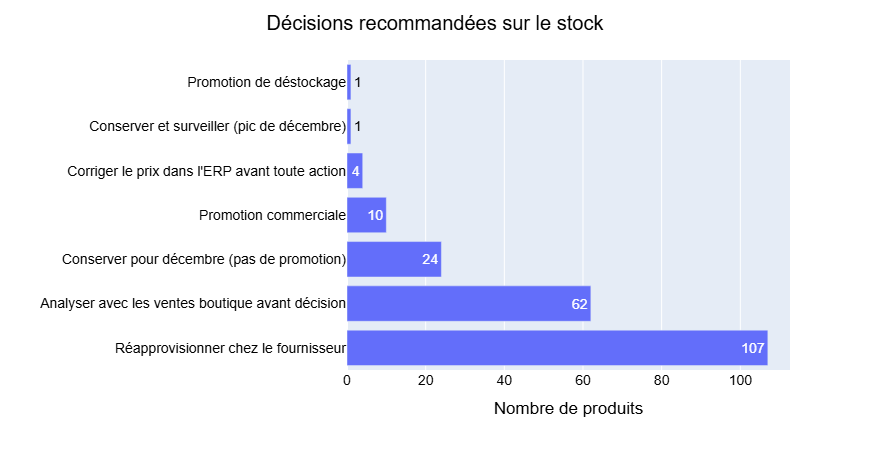

In [66]:
cible_unites = np.ceil(d["demande_ref_mensuelle"] * COUVERTURE_CIBLE_MOIS)
besoin_appro = d["statut_stock"].isin(["Rupture de stock", "Sous-stock"])
a_ecouler = d["statut_stock"].isin(["Surstock", "Stock dormant (aucune vente)"]) & ~saison
prix_suspect = d["vente_a_perte"] & ~bon

d["stock_cible_unites"] = cible_unites.fillna(0)
d["quantite_a_commander"] = np.where(besoin_appro, np.ceil(np.maximum(cible_unites - stock, 0)), 0)
d["cout_reappro_estime"] = (d["quantite_a_commander"] * d["purchase_price"]).round(2)
d["stock_excedentaire"] = np.where(a_ecouler, np.ceil(np.maximum(stock - cible_unites.fillna(0), 0)), 0)
d["valeur_stock_a_ecouler_cout"] = (d["stock_excedentaire"] * d["purchase_price"]).round(2)

# Remise indicative : on cède au plus PART_MARGE_CEDEE de la marge unitaire, plafonnée à REMISE_MAX (jamais de vente à perte)
remise = np.clip(PART_MARGE_CEDEE * d["taux_marque"], 0, REMISE_MAX).round(2)
d["remise_indicative"] = np.where(a_ecouler & ~prix_suspect, remise, np.nan)
d["prix_promo_ttc_indicatif"] = (d["price"] * (1 - d["remise_indicative"])).round(2)

d["decision"] = np.select(
    [prix_suspect, besoin_appro, d["statut_stock"] == "Surstock", (d["statut_stock"] == "Stock dormant (aucune vente)") & ~saison,
     (d["statut_stock"] == "Stock dormant (aucune vente)") & saison, d["statut_stock"] == "Surstock attendu (saisonnalité)",
     d["statut_stock"] == "Stock non publié (ventes web inconnues)"],
    ["Corriger le prix dans l'ERP avant toute action", "Réapprovisionner chez le fournisseur", "Promotion commerciale",
     "Promotion de déstockage", "Conserver et surveiller (pic de décembre)", "Conserver pour décembre (pas de promotion)",
     "Analyser avec les ventes boutique avant décision"], default="Aucune action")

ordre_niveau = {"Critique": 1, "Elevé": 2, "Moyen": 3, "A analyser": 4, "Information": 5, "Aucun": 6}

resume_decisions = (d[d["decision"] != "Aucune action"].groupby("decision")
                    .agg(nb_produits=("product_id", "count"), quantite_a_commander=("quantite_a_commander", "sum"),
                         cout_reappro=("cout_reappro_estime", "sum"), stock_excedentaire=("stock_excedentaire", "sum"),
                         valeur_a_ecouler_cout=("valeur_stock_a_ecouler_cout", "sum")).round(0).reset_index()
                    .sort_values("nb_produits", ascending=False))

display(resume_decisions)
fig = px.bar(resume_decisions, x="nb_produits", y="decision", orientation="h", text="nb_produits",
             labels={"nb_produits": "Nombre de produits", "decision": ""})
mise_en_forme(fig, "Décisions recommandées sur le stock", hauteur=450).show()

**Lecture et limites.** Ces recommandations sont une **aide à la décision**, pas un ordre : quantités et remises sont indicatives. Elles ignorent les ventes en boutique, les délais et minimums de commande des fournisseurs et l'historique de décembre (voir les pistes de l'étape 6). Les produits dont le prix est suspect sont **bloqués** (« Corriger le prix ») car toute promotion calculée sur un prix erroné serait fausse.

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">Etape 5.7 - Mise à disposition de la nouvelle table sur un fichier Excel</h3>
</div>

> **🛡️ Data governance :** l'export comporte des **colonnes de contrôle** (jonction, corrections, valeurs d'origine) pour que chacun puisse auditer le résultat, un **dictionnaire des données** et la **traçabilité** des sources. Aucun chemin de fichier n'y figure. Les colonnes sensibles (prix d'achat, marges, valorisations au coût) sont retirables de tous les onglets avec `EXPORT_COLONNES_SENSIBLES = False`.

In [68]:
colonnes_export = [
    "product_id", "id_web", "cle_jonction", "post_title", "product_type",
    "statut_jonction", "indicateur_merge", "origine_cle",
    "corr_price", "corr_stock", "corr_status", "corr_ventes", "corr_type", "vente_a_perte",
    "price_origine", "stock_quantity_origine", "stock_status_origine", "total_sales_origine",
    "onsale_web", "price", "taux_tva", "prix_ht", "purchase_price", "marge_unitaire", "taux_marque", "taux_marge",
    "stock_quantity", "stock_status", "valo_stock_cout", "valo_stock_vente_ht", "ventes_mensuelles", "couverture_mois", "couverture_ref_mois",
    "total_sales", "ca_ttc", "ca_ht", "marge_totale", "classe_abc_ventes",
    "statut_stock", "decision", "stock_cible_unites", "quantite_a_commander", "cout_reappro_estime",
    "stock_excedentaire", "valeur_stock_a_ecouler_cout", "remise_indicative", "prix_promo_ttc_indicatif"]
df_final = df_merge[colonnes_export].sort_values("product_id").reset_index(drop=True)
assert len(df_final) == N_ERP_INITIAL and df_final["product_id"].is_unique
tracer("5.7 export", "produits", df_final, "une ligne par produit ERP, aucune ligne perdue")

def pour_export(df):
    """Retire les colonnes sensibles si le paramètre l'exige."""
    return df if EXPORT_COLONNES_SENSIBLES else df.drop(columns=[c for c in COLONNES_SENSIBLES if c in df.columns])

In [70]:
colonnes_alertes = ["product_id", "post_title", "product_type", "classe_abc_ventes", "stock_quantity", "total_sales",
                    "couverture_mois", "couverture_ref_mois", "valo_stock_cout", "statut_stock"]
alertes_stock = (df_final[~df_final["statut_stock"].isin(["Stock normal", "Hors périmètre ou inactif"])]
                 [colonnes_alertes].sort_values(["valo_stock_cout"], ascending=[True]))
colonnes_decision = ["product_id", "post_title", "product_type", "statut_stock", "decision", "stock_quantity",
                     "total_sales", "stock_cible_unites", "quantite_a_commander", "cout_reappro_estime", "stock_excedentaire",
                     "valeur_stock_a_ecouler_cout", "remise_indicative", "prix_promo_ttc_indicatif"]
decisions_stock = (df_final[df_final["decision"] != "Aucune action"][colonnes_decision]
                   .sort_values([ "valeur_stock_a_ecouler_cout"], ascending=[True]))

# Synthèse par famille : CA, marge, stock, alertes
stat = df_final[df_final["product_type"] != "Bon cadeau"].pivot_table(index="product_type", columns="statut_stock", values="product_id", aggfunc="count", fill_value=0)
synthese_famille = (stock_famille.merge(table_type[["product_type", "ca_ht", "part_ca"]], on="product_type", how="left")
                    .merge(synthese_marge[["product_type", "marge_totale", "taux_marque_pondere"]], on="product_type", how="left")
                    .merge(stat.reset_index(), on="product_type", how="left"))

synthese_globale = pd.concat([
    kpi_stock,
    pd.DataFrame([("CA web du mois estimé HT (€)", round(perimetre["ca_ht"].sum())),
                  ("Marge web du mois estimée (€)", round(marge_ok["marge_totale"].sum())),
                  ("Produits à réapprovisionner", int((df_final["decision"] == "Réapprovisionner chez le fournisseur").sum())),
                  ("Produits en promotion recommandée", int(df_final["decision"].isin(["Promotion commerciale", "Promotion de déstockage"]).sum())),
                  ("Valeur du stock à écouler au coût (€)", round(df_final["valeur_stock_a_ecouler_cout"].sum())),
                  ("Anomalies de données tracées", len(anomalies))], columns=["indicateur", "valeur"])], ignore_index=True)

dictionnaire = pd.DataFrame([
    ("product_id", "Identifiant produit ERP", "ERP"), ("id_web", "Identifiant web issu de la table de liaison", "Liaison"),
    ("cle_jonction", "Clé utilisée pour la jonction ERP/web", "Calculée"), ("statut_jonction", "Résultat de la jonction par produit", "Calculée"),
    ("indicateur_merge", "Indicateur pandas du merge (both = présent dans ERP et web)", "Calculée"),
    ("origine_cle", "Clé issue de la liaison ou du guid du site (repli)", "Calculée"),
    ("corr_price / corr_stock / corr_status / corr_ventes / corr_type", "VRAI si la valeur a été corrigée au nettoyage", "Nettoyage"),
    ("price_origine / stock_quantity_origine / stock_status_origine / total_sales_origine", "Valeur avant correction", "Source"),
    ("vente_a_perte", "VRAI si le prix de vente HT est inférieur au prix d'achat (anomalie signalée)", "Calculée"),
    ("price / prix_ht", "Prix de vente TTC / HT", "ERP / calculée"), ("purchase_price", "Prix d'achat HT (SENSIBLE)", "ERP"),
    ("taux_marque / taux_marge", "Marge ÷ prix de vente HT / marge ÷ prix d'achat (SENSIBLE)", "Calculée"),
    ("stock_quantity / stock_status", "Quantité et statut de stock au 31 octobre (après nettoyage)", "ERP"),
    ("total_sales", "Ventes web du 1er au 31 octobre (après nettoyage)", "Web"), ("ca_ht / ca_ttc", "CA web du mois estimé (prix x ventes)", "Calculée"),
    ("couverture_mois", "Stock ÷ ventes mensuelles (mois de ventes web)", "Calculée"),
    ("couverture_ref_mois", "Stock ÷ demande de référence (champagne : demande de décembre estimée)", "Calculée"),
    ("classe_abc_ventes", "Classe ABC d'après le CA web du mois (A = 50 premiers %, B jusqu'à 80 %, C = le reste)", "Calculée"),
    ("statut_stock", "Système d'alerte de stock (1 = le plus urgent)", "Calculée"),
    ("decision", "Décision recommandée : réapprovisionner, promotion, conserver, corriger le prix…", "Calculée"),
    ("quantite_a_commander / stock_cible_unites", "Quantité indicative à commander pour atteindre la couverture cible", "Calculée"),
    ("stock_excedentaire / remise_indicative / prix_promo_ttc_indicatif", "Stock à écouler et promotion indicative (marge préservée)", "Calculée")],
    columns=["colonne", "description", "origine"])

lisez_moi = pd.DataFrame([
    ("Contexte", "Données ERP au 31 octobre ; ventes web du 1er au 31 octobre ; analyse début novembre"),
    ("Règle champagne", f"Surstock de la famille « {FAMILLE_SAISONNIERE} » considéré comme normal (préparation de décembre)"),
    ("Hypothèse à calibrer", f"Ventes de décembre = {COEF_SAISON_DECEMBRE} x ventes d'octobre pour la famille saisonnière"),
    ("Seuils de stock", f"Sous-stock < {SEUIL_SOUS_STOCK_MOIS} mois ; surstock > {SEUIL_SURSTOCK_MOIS} mois ; cible {COUVERTURE_CIBLE_MOIS} mois de ventes"),
    ("Limite", "Ventes boutique non incluses : couvertures de stock surestimées"),
    ("Données sensibles", "Prix d'achat, marges et valorisations au coût : diffusion restreinte" + ("" if EXPORT_COLONNES_SENSIBLES else " (colonnes retirées de cet export)")),
    ("Onglets", "produits · alertes_stock · decisions_stock · synthese_globale · synthese_famille · abc_ventes · jonction · "
                "controle_qualite · anomalies · outliers_prix · tracabilite · journal_traitement · dictionnaire")],
    columns=["rubrique", "contenu"])

feuilles = {"LISEZ-MOI": lisez_moi, "produits": df_final, "alertes_stock": alertes_stock, "decisions_stock": decisions_stock,
            "synthese_globale": synthese_globale, "synthese_famille": synthese_famille, "abc_ventes": abc_ventes,
            "jonction": recap_jonction, "controle_qualite": controle_qualite, "anomalies": pd.DataFrame(anomalies).drop_duplicates().reset_index(drop=True),
            "outliers_prix": outliers_prix, "tracabilite": tracabilite_sources, "journal_traitement": pd.DataFrame(journal_pipeline),
            "dictionnaire": dictionnaire}

with pd.ExcelWriter(DOSSIER_SORTIE / "df_merge.xlsx") as xl:
    for nom, feuille in feuilles.items():
        pour_export(feuille).to_excel(xl, sheet_name=nom, index=False)         # index=False : pas de colonne d'index parasite
print(f"Fichier Excel généré : {len(feuilles)} onglets -> {', '.join(feuilles)}")
print(f"Produits exportés : {len(df_final)} | alertes : {len(alertes_stock)} | décisions à prendre : {len(decisions_stock)}")

Fichier Excel généré : 14 onglets -> LISEZ-MOI, produits, alertes_stock, decisions_stock, synthese_globale, synthese_famille, abc_ventes, jonction, controle_qualite, anomalies, outliers_prix, tracabilite, journal_traitement, dictionnaire
Produits exportés : 825 | alertes : 208 | décisions à prendre : 209


<div style="background-color: RGB(51,165,182);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Recommandations d'amélioration des processus de traitement et d'analyse des données</h2>
</div>

<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">6.1 - Synthèse chiffrée</h3>
</div>

In [71]:
display(synthese_globale)
display(feuilles["anomalies"].groupby(["source", "champ", "constat"]).size().rename("nb_lignes").reset_index())
display(controle_qualite[["source", "regle", "nb_violations_avant", "nb_violations_apres", "resultat"]])

,indicateur,valeur
0,Références au catalogue ERP,824.0
1,Références en stock (quantité > 0),732.0
2,Références en rupture (quantité = 0),92.0
3,Unités en stock,17799.0
4,Valeur du stock au coût d'achat (€),298322.0
5,Valeur du stock au prix de vente HT (€),443312.0
6,Stock médian par référence (unités),18.0
7,Ventes web du mois (unités),5744.0
8,Couverture globale du périmètre web (mois de v...,2.9
9,Couverture médiane par produit (mois),2.4


,source,champ,constat,nb_lignes
0,erp,price,prix de vente HT inférieur au prix d'achat (ve...,4
1,erp,price,prix négatif ; ratio prix/achat cohérent après...,3
2,erp,stock_quantity,stock négatif,2
3,erp,stock_status,statut incohérent avec stock_quantity,2
4,jonction,valeur,incohérence entre onsale_web (ERP) et présence...,2
5,web,total_sales,ventes mensuelles négatives (retours ?),2
6,web,valeur,type de produit manquant,1
7,web,valeur,type incohérent avec le titre (règle « Coteaux...,1
8,web,valeur,type incohérent avec le titre (règle « Eau de ...,12


,source,regle,nb_violations_avant,nb_violations_apres,resultat
0,erp,product_id unique,0,0,OK
1,erp,prix de vente renseigné et > 0,3,0,OK
2,erp,quantité en stock >= 0,2,0,OK
3,erp,stock_status cohérent avec stock_quantity,2,0,OK
4,erp,prix d'achat renseigné et > 0,0,0,OK
5,erp,prix de vente TTC >= prix d'achat HT,7,4,A SIGNALER
6,erp,onsale_web valant 0 ou 1,0,0,OK
7,web,ligne entièrement vide,83,0,OK
8,web,fiche produit sans sku,2,2,A SIGNALER
9,web,sku dupliqué parmi les fiches produit,0,0,OK


<div style="border: 1px solid RGB(51,165,182);" >
<h3 style="margin: auto; padding: 20px; color: RGB(51,165,182); ">6.2 - Recommandations</h3>
</div>

**A. Data governance**
- **Désigner un responsable de chaque source** (ERP : commerce et logistique ; web : équipe site) et lui transmettre à chaque exécution l'onglet `anomalies` avec un suivi des corrections ; une erreur corrigée dans l'ERP ne doit plus réapparaître.
- Faire **vivre le dictionnaire des données** (onglet `dictionnaire`), le tenir sous contrôle de version et y marquer les colonnes sensibles.
- Conserver le contrôle qualité **avant / après** comme **indicateur de suivi** : nombre de violations par règle, mois après mois.
- Limiter la diffusion des fichiers contenant prix d'achat et marges ; utiliser `EXPORT_COLONNES_SENSIBLES = False` pour les destinataires qui n'en ont pas besoin. Ne jamais afficher ni exporter les chemins des sources.

**B. Qualité à la source**
- **Contrôles bloquants à la saisie dans l'ERP** : prix > 0, stock ≥ 0, prix de vente HT ≥ prix d'achat (interdiction de revente à perte), statut de stock **calculé** à partir de la quantité et non saisi.
- **Alerte de vraisemblance** sur le rapport prix de vente / prix d'achat (très stable dans ce catalogue) pour détecter les décalages de virgule (cas du produit 4355).
- **Clé unique partagée** ERP / web : stocker le `product_id` dans un champ du site (ou utiliser le `sku`) supprimerait la table de liaison, incomplète. Interdire les `sku` à suffixe et traiter le bon cadeau comme un type de produit distinct.
- Contrôler en continu la cohérence `onsale_web` (ERP) / présence sur le site et le **type de produit** (eaux-de-vie classées « Vin », vin tranquille classé « Champagne »). Exporter du web uniquement les fiches produit (sans visuels ni lignes vides).

**C. Gestion du stock : ce que fait le notebook et comment l'affiner**
- Le notebook fournit un **statut de stock, un niveau d'alerte, une décision et des quantités / remises indicatives par produit**, dans l'onglet `decisions_stock`.
- **Calibrer la saisonnalité** : remplacer `COEF_SAISON_DECEMBRE` (hypothèse) par le rapport réel décembre / octobre de l'an dernier, famille par famille (le champagne n'est probablement pas la seule : spiritueux et cadeaux de fin d'année).
- **Passer des seuils fixes à un point de commande** : stock de sécurité + délai de livraison de chaque fournisseur, et prise en compte des minimums et conditionnements de commande.
- Enrichir la classification en **ABC-XYZ** (XYZ = régularité des ventes) : un produit A régulier se réapprovisionne automatiquement, un produit C erratique à la demande.
- Pour les surstocks hors champagne : privilégier les **offres groupées** (caisses mixtes, cadeaux) aux simples baisses de prix, et vérifier la marge restante avant toute remise.
- Traiter le **stock des produits non publiés** : capital immobilisé sans CA web, à confronter aux ventes en boutique avant décision.

**D. Données manquantes pour des analyses plus fiables**
- Intégrer les **ventes en boutique** : le stock est commun aux deux canaux, la couverture calculée avec les seules ventes web est surestimée.
- Extraire les **lignes de commande datées** sur 12 mois (et non un total mensuel) : saisonnalité, tendance, prévision de la demande et rotation réelle.
- Fournir le **taux de TVA par produit** et les **délais fournisseurs**.

**E. Processus d'analyse**
- Passer du notebook à un **pipeline planifié** (extraction → contrôle qualité → nettoyage → jonction → alertes → export), le notebook restant le support de présentation ; versionner le code et figer les versions des librairies.
- Conserver les **assertions** (aucune ligne perdue, aucune valeur négative restante) : le traitement doit échouer visiblement plutôt que produire un résultat faux.
- Alimenter un **tableau de bord** de suivi mensuel : taux de rupture, couverture par famille, valeur du stock dormant, nombre d'alertes critiques, valeur des promotions engagées.